<a href="https://colab.research.google.com/github/amoghsharma6996/AmoghKumarSharma23BDS0063/blob/main/EDA_Phase1_Amogh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA on Student Performance Dataset

**Name:** Amogh Kumar Sharma
**Reg No:** 23BDS0063
**Course:** BCSE331L - Exploratory Data Analysis

Dataset: [student-mat.csv](https://raw.githubusercontent.com/salemprakash/EDA/main/Data/student-mat.csv), Student Math Performance dataset (395 students, 33 columns).

This notebook has all the phases one after the other:
- Phase 1: basic EDA (loading, statistics, missing data, cleaning, transformation, plots)
- Phase 2: 1D / 2D / 3D statistics, K-Means and hierarchical clustering
- Phase 3a: Principal Component Analysis (PCA)
- Phase 3b: Simple Linear Regression

# Phase 1 - Basic EDA

Phase 1 tasks:
1. Loading the dataset
2. Basic statistical analysis
3. Handling missing data
4. Data cleaning
5. Data transformation
6. Univariate analysis
7. Bivariate analysis
8. Multivariate analysis


## 0. Importing required libraries
Basic libraries needed for loading data, doing stats, and plotting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
%matplotlib inline


## 1. Loading the Dataset
Reading the csv file from this folder. If it is not there, it is read from the GitHub link given in the assignment.

In [2]:
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/student-mat.csv"

# use the local csv if present, otherwise download it
import os
for name in ["student-mat.csv", "student-mat (1).csv"]:
    if os.path.exists(name):
        df = pd.read_csv(name)
        break
else:
    df = pd.read_csv(url)

In [3]:
# checking shape of dataset -> (rows, columns)
print("Shape of dataset:", df.shape)

# checking column names
print("\nColumn names:")
print(df.columns.tolist())


Shape of dataset: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [4]:
# quick info about datatypes and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         393 non-null    str  
 2   age         395 non-null    int64
 3   address     394 non-null    str  
 4   famsize     394 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   393 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

## 2. Applying Basic Statistical Analysis
Using `describe()` to get mean, std, min, max, quartiles etc. for the numeric columns.
Also checking value counts for a few categorical columns.

In [5]:
# statistical summary of all numeric columns
df.describe()


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [6]:
# describe() for categorical columns too
df.describe(exclude=np.number)


,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,395,393,394,394,395,395,395,395,395,393,395,395,395,395,395,395,395
unique,2,2,3,2,3,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,yes,yes,yes,yes,no
freq,349,208,304,280,348,141,217,145,273,343,242,214,201,314,375,329,263


In [7]:
# checking some individual stats for the final grade column (G3)
print("Mean of G3:", df['G3'].mean())
print("Median of G3:", df['G3'].median())
print("Mode of G3:", df['G3'].mode()[0])
print("Std Dev of G3:", df['G3'].std())
print("Variance of G3:", df['G3'].var())


Mean of G3: 10.415189873417722
Median of G3: 11.0
Mode of G3: 10
Std Dev of G3: 4.5814426109978434
Variance of G3: 20.989616397866733


## 3. Handling Missing Data
First checking the null values. This file also uses `?` for unknown entries, and pandas does not count those as missing,
so they are converted to missing values in the next step.

In [8]:
# checking null values column-wise
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values in dataset:", df.isnull().sum().sum())


Missing values per column:
school        0
sex           2
age           0
address       1
famsize       1
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     2
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values in dataset: 6


In [9]:
# '?' means unknown in this file, so turning it into a proper missing value
print("'?' entries per column:")
print((df == '?').sum()[(df == '?').sum() > 0])
df = df.replace('?', np.nan)
print("\nTotal missing values now:", df.isnull().sum().sum())

# numeric columns -> fill with median
num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# text columns -> fill with mode (most common value)
cat_cols = df.select_dtypes(exclude=np.number).columns
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after handling:", df.isnull().sum().sum())

'?' entries per column:
address    2
Pstatus    6
dtype: int64

Total missing values now: 14
Missing values after handling: 0


## 4. Data Cleaning
Checking for duplicate rows and any obvious inconsistencies in the data.

In [10]:
# checking for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

# dropping duplicates if any
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)


Number of duplicate rows: 0
Shape after removing duplicates: (395, 33)


In [11]:
# checking unique values in some categorical columns to spot any weird/inconsistent entries
for col in ['school', 'sex', 'address', 'famsize', 'Pstatus', 'higher', 'internet']:
    print(col, "->", df[col].unique())


school -> <StringArray>
['GP', 'MS']
Length: 2, dtype: str
sex -> <StringArray>
['F', 'M']
Length: 2, dtype: str
address -> <StringArray>
['U', 'R']
Length: 2, dtype: str
famsize -> <StringArray>
['GT3', 'LE3']
Length: 2, dtype: str
Pstatus -> <StringArray>
['A', 'T']
Length: 2, dtype: str
higher -> <StringArray>
['yes', 'no']
Length: 2, dtype: str
internet -> <StringArray>
['no', 'yes']
Length: 2, dtype: str


In [12]:
# stripping any extra spaces from column names,
df.columns = df.columns.str.strip()

# resetting index after dropping duplicates so index stays continuous
df = df.reset_index(drop=True)


Checking the final grades that are 0. A grade of 0 next to a normal G1 or G2 usually means the student did not sit the final exam, so it is worth knowing how many there are.

In [13]:
print("Students with G3 = 0:", (df['G3'] == 0).sum())
print("Of these, students whose G2 was above 0:", ((df['G3'] == 0) & (df['G2'] > 0)).sum())
# keeping them in the data, they are real records and end up in the Low performance group

Students with G3 = 0: 38
Of these, students whose G2 was above 0: 25


## 5. Data Transformation
Creating a couple of new/derived columns and encoding categorical variables so that they
can be used later for analysis (like correlation, multivariate plots etc.)

In [14]:
# Grades G1, G2, G3 are on a 0-20 scale, adding an average grade column
df['avg_grade'] = (df['G1'] + df['G2'] + df['G3']) / 3
# just a simple bucketing: Low / Medium / High
def grade_bucket(g):
    if g < 10:
        return 'Low'
    elif g < 15:
        return 'Medium'
    else:
        return 'High'

df['performance'] = df['G3'].apply(grade_bucket)

df[['G1', 'G2', 'G3', 'avg_grade', 'performance']].head()


,G1,G2,G3,avg_grade,performance
0,5,6,6,5.666667,Low
1,5,5,6,5.333333,Low
2,7,8,10,8.333333,Medium
3,15,14,15,14.666667,High
4,6,10,10,8.666667,Medium


In [15]:
# label encoding some binary categorical columns (yes/no -> 1/0) so they're easier to use in plots/corr
binary_cols = ['schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

for col in binary_cols:
    df[col + '_enc'] = df[col].map({'yes': 1, 'no': 0})

df[binary_cols + [c + '_enc' for c in binary_cols]].head()


,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,schoolsup_enc,famsup_enc,paid_enc,activities_enc,nursery_enc,higher_enc,internet_enc,romantic_enc
0,yes,no,no,no,yes,yes,no,no,1,0,0,0,1,1,0,0
1,no,yes,no,no,no,yes,yes,no,0,1,0,0,0,1,1,0
2,yes,no,yes,no,yes,yes,yes,no,1,0,1,0,1,1,1,0
3,no,yes,yes,yes,yes,yes,yes,yes,0,1,1,1,1,1,1,1
4,no,yes,yes,no,yes,yes,no,no,0,1,1,0,1,1,0,0


## 6. Univariate Analysis
Looking at individual columns one at a time. Using histograms, count plots and a box plot.

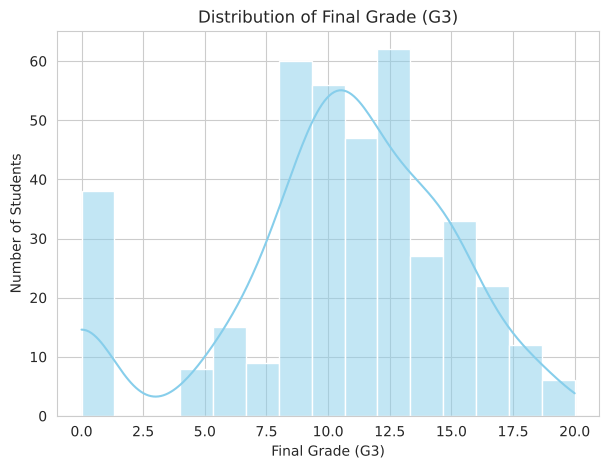

In [16]:
# Plot 1: Histogram of final grade (G3)
plt.figure(figsize=(7,5))
sns.histplot(df['G3'], bins=15, kde=True, color='skyblue')
plt.title("Distribution of Final Grade (G3)")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()


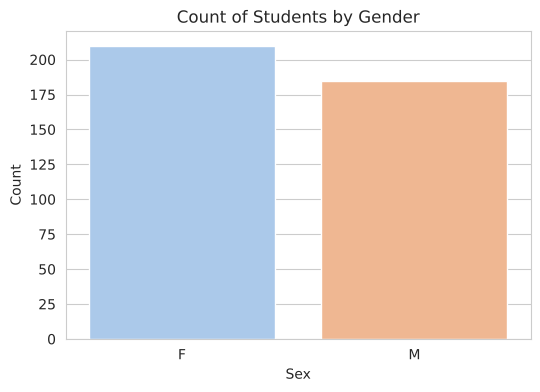

In [17]:
# Plot 2: Count plot of students by sex
plt.figure(figsize=(6,4))
sns.countplot(x='sex', hue='sex', data=df, palette='pastel', legend=False)
plt.title("Count of Students by Gender")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()


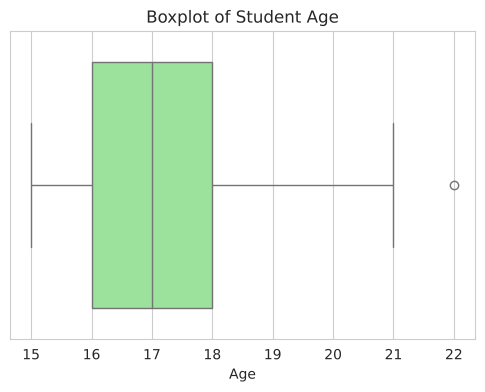

In [18]:
# Plot 3: Box plot for age to check spread and outliers
plt.figure(figsize=(6,4))
sns.boxplot(x=df['age'], color='lightgreen')
plt.title("Boxplot of Student Age")
plt.xlabel("Age")
plt.show()


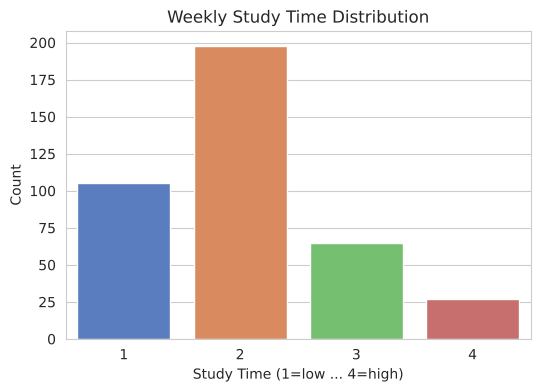

In [19]:
# Plot 4 (extra): Distribution of weekly study time
plt.figure(figsize=(6,4))
sns.countplot(x='studytime', hue='studytime', data=df, palette='muted', legend=False)
plt.title("Weekly Study Time Distribution")
plt.xlabel("Study Time (1=low ... 4=high)")
plt.ylabel("Count")
plt.show()


## 7. Bivariate Analysis
Looking at relationship between two variables at a time.

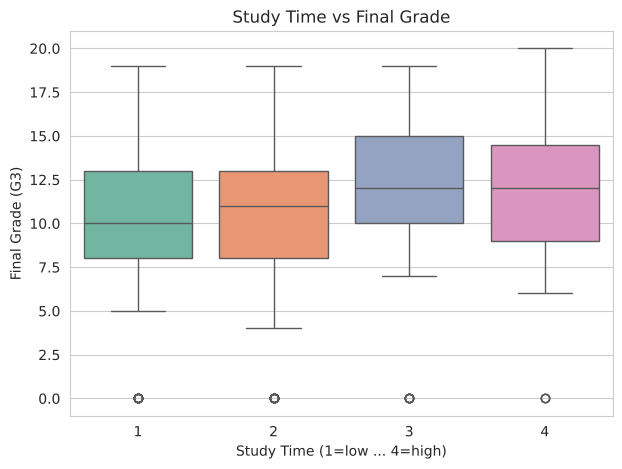

In [20]:
# Plot 1: Study time vs Final grade
plt.figure(figsize=(7,5))
sns.boxplot(x='studytime', y='G3', hue='studytime', data=df, palette='Set2', legend=False)
plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time (1=low ... 4=high)")
plt.ylabel("Final Grade (G3)")
plt.show()


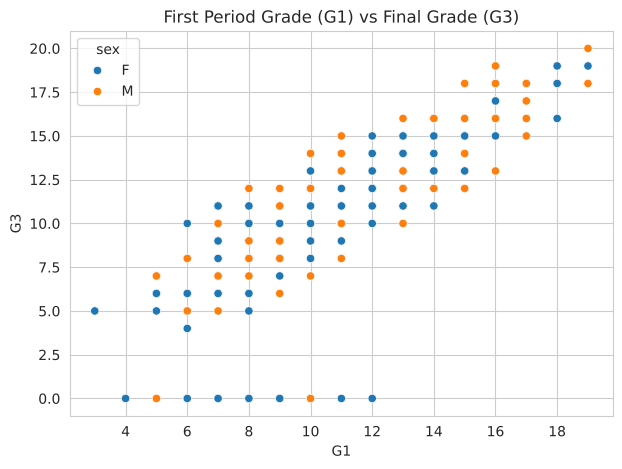

In [21]:
# Plot 2: Scatter plot - G1 vs G3 (first period grade vs final grade)
plt.figure(figsize=(7,5))
sns.scatterplot(x='G1', y='G3', data=df, hue='sex')
plt.title("First Period Grade (G1) vs Final Grade (G3)")
plt.xlabel("G1")
plt.ylabel("G3")
plt.show()


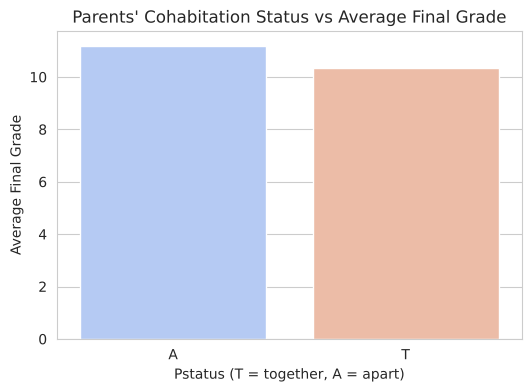

In [22]:
# Plot 3: Average final grade by parents' cohabitation status
plt.figure(figsize=(6,4))
sns.barplot(x='Pstatus', y='G3', hue='Pstatus', data=df, palette='coolwarm', errorbar=None, legend=False)
plt.title("Parents' Cohabitation Status vs Average Final Grade")
plt.xlabel("Pstatus (T = together, A = apart)")
plt.ylabel("Average Final Grade")
plt.show()


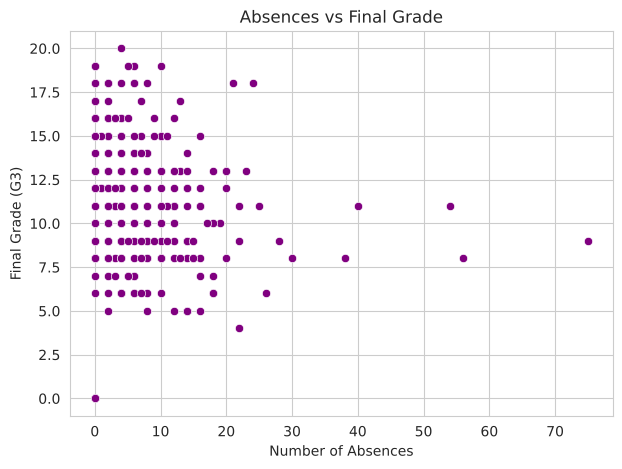

In [23]:
# Plot 4 (extra): Correlation between absences and final grade
plt.figure(figsize=(7,5))
sns.scatterplot(x='absences', y='G3', data=df, color='purple')
plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")
plt.show()


## 8. Multivariate Analysis
Looking at relationships between 3 or more variables together.

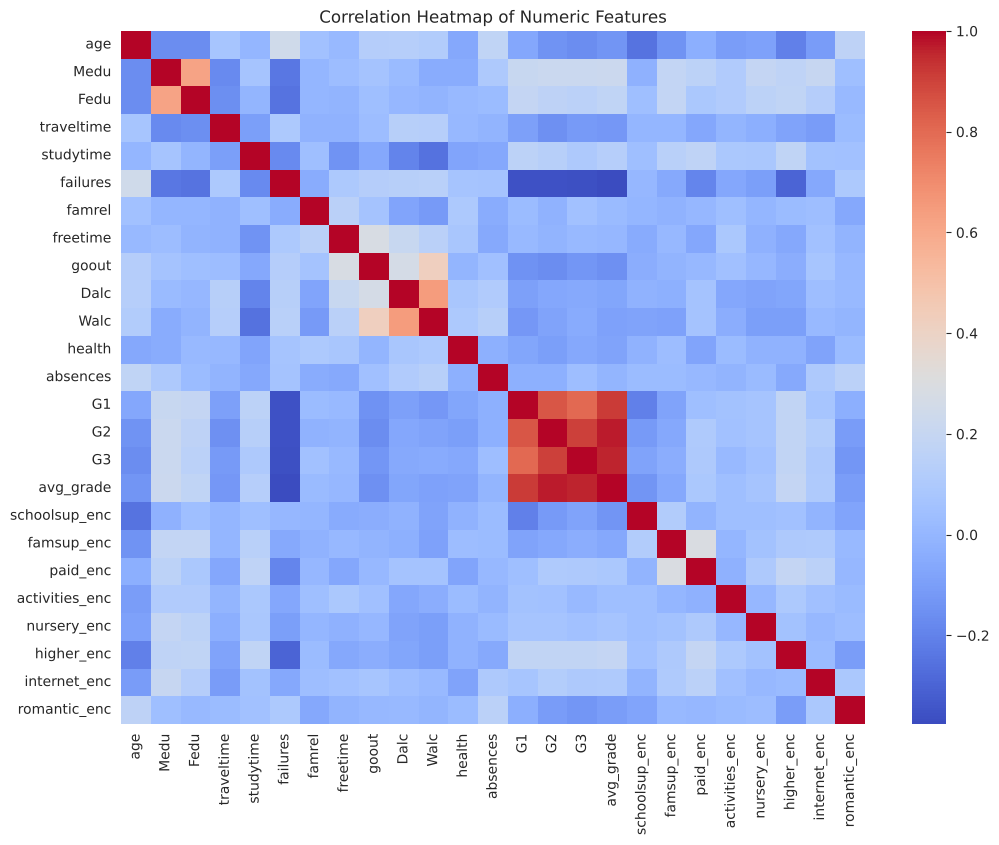

In [24]:
# Plot 1: Correlation heatmap of numeric columns
plt.figure(figsize=(12,9))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, cmap='coolwarm', annot=False)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()


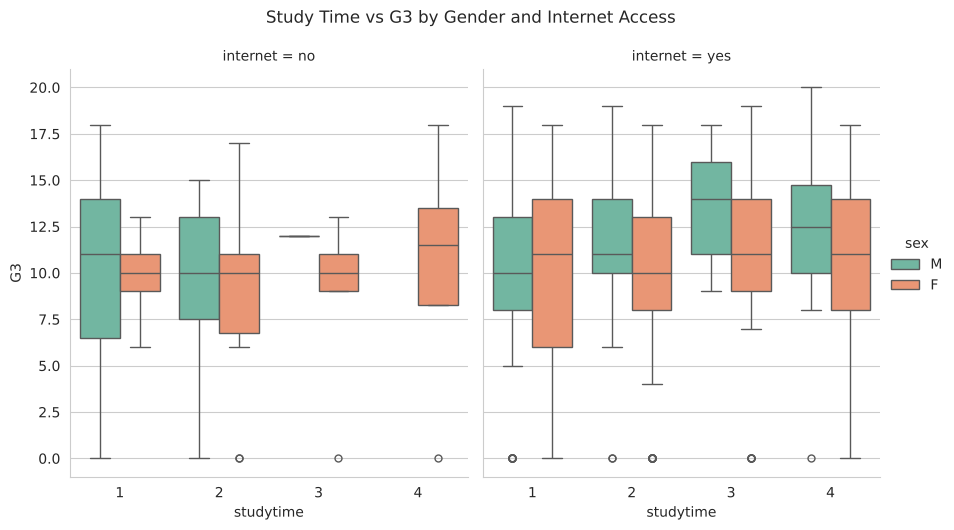

In [25]:
# Plot 2: Study time vs G3, split by gender (hue) and internet access (col)
g = sns.catplot(x='studytime', y='G3', hue='sex', col='internet',
                 data=df, kind='box', palette='Set2', height=5, aspect=0.9)
g.fig.suptitle("Study Time vs G3 by Gender and Internet Access", y=1.05)
plt.show()


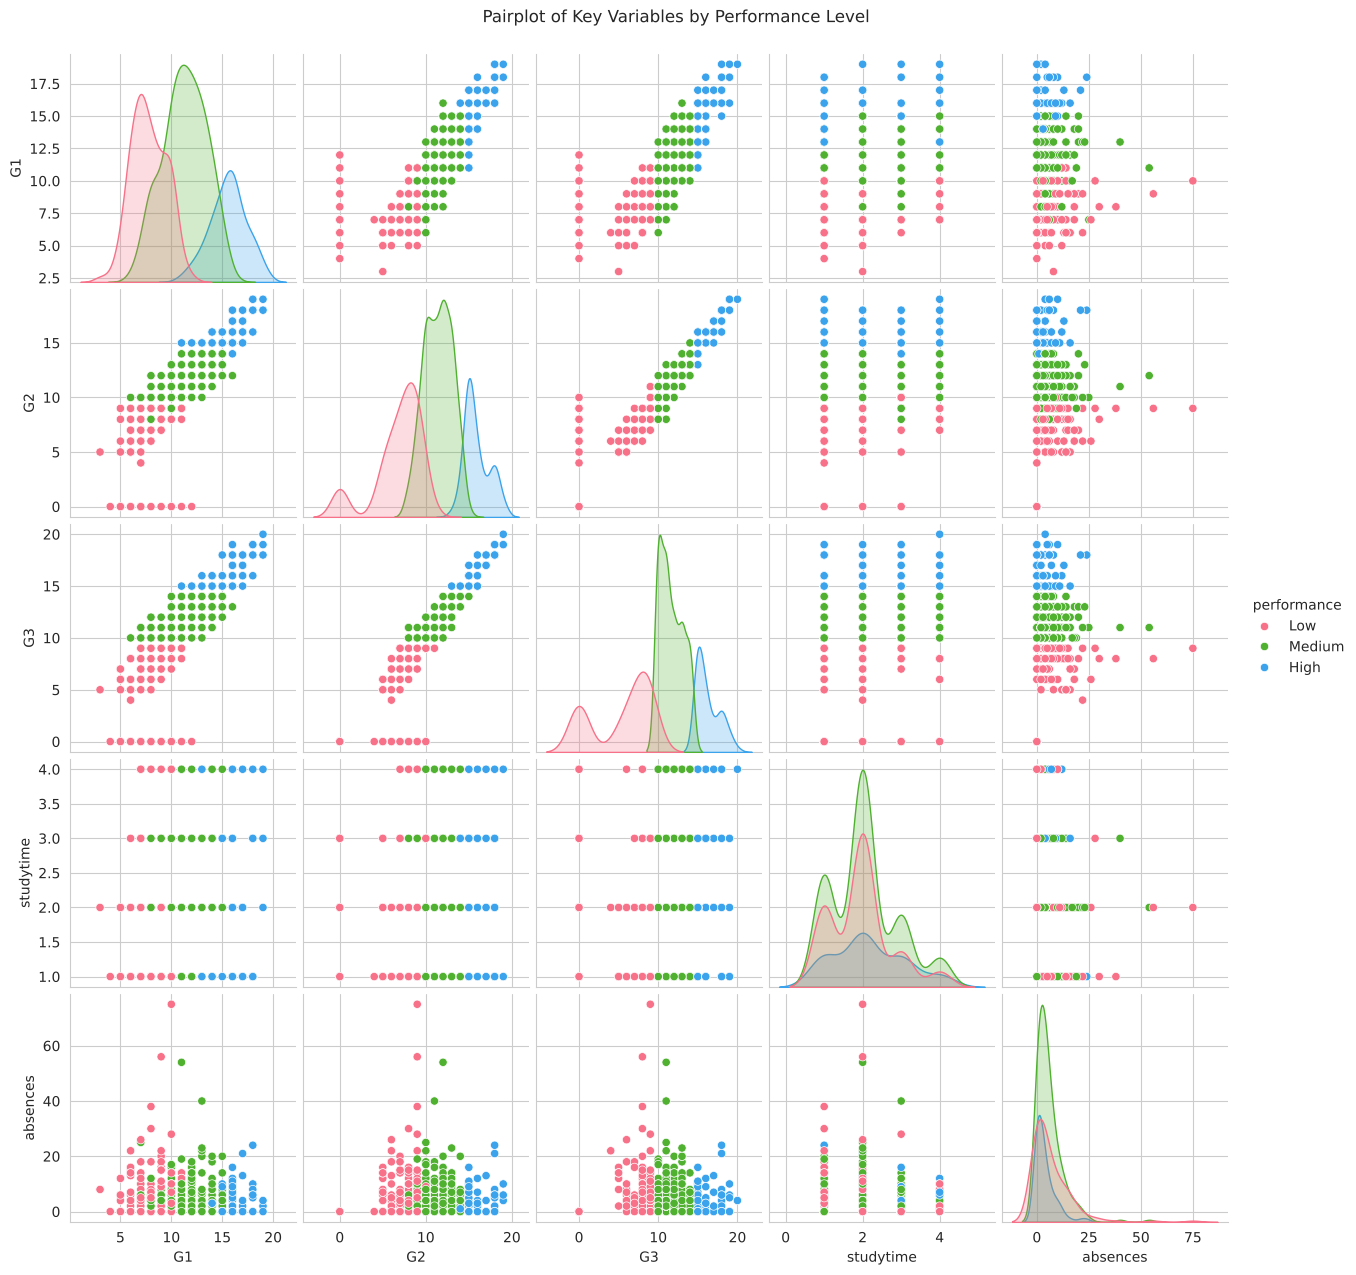

In [26]:
# Plot 3: Pairplot of a few important numeric columns, colored by performance bucket
cols_to_plot = ['G1', 'G2', 'G3', 'studytime', 'absences', 'performance']
sns.pairplot(df[cols_to_plot], hue='performance', palette='husl')
plt.suptitle("Pairplot of Key Variables by Performance Level", y=1.02)
plt.show()


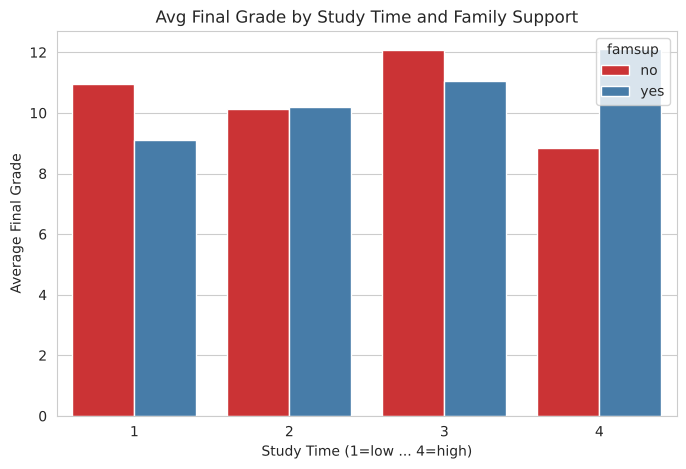

In [27]:
# Plot 4 : Avg final grade by study time and family support, grouped bar chart
pivot_df = df.groupby(['studytime', 'famsup'])['G3'].mean().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(x='studytime', y='G3', hue='famsup', data=pivot_df, palette='Set1')
plt.title("Avg Final Grade by Study Time and Family Support")
plt.xlabel("Study Time (1=low ... 4=high)")
plt.ylabel("Average Final Grade")
plt.show()


## Conclusion (Phase 1)

- The raw file had 6 missing values (`sex`, `address`, `famsize`, `schoolsup`) and 8 entries marked `?` (`address`, `Pstatus`). All 14 were treated as missing and filled with the most common value of that column.
- There were no duplicate rows.
- New columns (`avg_grade`, `performance`) were created during transformation to help with later analysis.
- 38 students have a final grade (G3) of 0. These are most likely students who did not take the final exam. They were kept in the data and fall in the `Low` group.
- From the univariate plots, most students score in the mid-range for final grades, and study time is fairly skewed towards lower values (1-2).
- From the bivariate plots, there seems to be a positive relation between study time and final grade, and a strong positive relation between G1/G2 and G3 (expected, since they are earlier grades in the same subject).
- The correlation heatmap and pairplot in the multivariate section show G1, G2 and G3 are highly correlated with each other, while other features like absences have weaker correlation with final grade.

This completes all Phase 1 requirements.

# Phase 2 – Statistical Analysis (1D / 2D / 3D) and Clustering

**Name:** Amogh Kumar Sharma
**Reg No:** 23BDS0063

Phase 1 covered loading, cleaning, transforming and basic univariate/bivariate/multivariate plots.
Phase 2 goes deeper into the statistics side and adds clustering:

9. 1D (Univariate) Statistical Analysis
10. 2D (Bivariate) Statistical Analysis
11. 3D (Multivariate) Statistical Analysis
12. K-Means Clustering
13. Hierarchical Clustering

This uses the same `df` that was already loaded and cleaned in Phase 1, so run all the Phase 1 cells above first.

## Extra imports needed for Phase 2
`scipy` for statistical tests + distance/linkage, `sklearn` for scaling/clustering/regression, and
`mplot3d` for the 3D plot.

**Note on R equivalents:** this notebook is kept in Python (per the assignment instructions — same
notebook, not a new one), so wherever the brief asks for an R function, the equivalent Python call is
used and noted in a comment: `e1071::skewness`/`kurtosis` → `scipy.stats.skew`/`kurtosis`,
`prop.table()` → `pd.crosstab(..., normalize=...)`, `aggregate()` → `groupby().agg()`, `cor()` →
`.corr()`/`scipy.stats.pearsonr`/`spearmanr`, `dist()` → `scipy.spatial.distance.pdist`, `hclust()` →
`scipy.cluster.hierarchy.linkage`, `cutree()` → `fcluster`, `kmeans()` → `sklearn.cluster.KMeans`,
`scale()` → `sklearn.preprocessing.StandardScaler`.


In [28]:
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression

from mpl_toolkits.mplot3d import Axes3D


## Q2-3. Summary Statistics (1D)
Computing Mean, Median, Min, Max, Range, Variance, Std Dev, IQR, Skewness and Kurtosis for the three
key numeric columns (`G3`, `absences`, `studytime`), storing everything in one structured DataFrame.
Skewness/Kurtosis use `scipy.stats.skew`/`kurtosis` with `bias=False`, matching R's
`e1071::skewness`/`kurtosis` (type = 2) — the standard "sample" adjusted versions.

In [29]:
cols_1d = ['G3', 'absences', 'studytime']

summary_stats = pd.DataFrame({
    col: {
        'Mean': df[col].mean(),
        'Median': df[col].median(),
        'Minimum': df[col].min(),
        'Maximum': df[col].max(),
        'Range': df[col].max() - df[col].min(),
        'Variance': df[col].var(),
        'Std_Dev': df[col].std(),
        'IQR': df[col].quantile(0.75) - df[col].quantile(0.25),
        # scipy.stats.skew/kurtosis(bias=False) ~= e1071::skewness/kurtosis(type=2) in R
        'Skewness': stats.skew(df[col], bias=False),
        'Kurtosis': stats.kurtosis(df[col], bias=False)
    }
    for col in cols_1d
}).T

summary_stats.round(3)


,Mean,Median,Minimum,Maximum,Range,Variance,Std_Dev,IQR,Skewness,Kurtosis
G3,10.415,11.0,0.0,20.0,20.0,20.990,4.581,6.0,-0.733,0.403
absences,5.709,4.0,0.0,75.0,75.0,64.050,8.003,8.0,3.672,21.719
studytime,2.035,2.0,1.0,4.0,3.0,0.704,0.839,1.0,0.632,-0.014


## Q4. Frequency & Relative Frequency Distribution (Categorical Variable)
Using `internet` (does the student have internet access at home?) as the categorical variable.
`value_counts()` gives the frequency table; `value_counts(normalize=True)` gives the relative
frequency table — the Python equivalent of R's `table()` / `prop.table(table())`.

In [30]:
cat_var = 'internet'

freq_table = df[cat_var].value_counts()
rel_freq_table = df[cat_var].value_counts(normalize=True)   # equiv. to R's prop.table(table(x))

freq_dist = pd.DataFrame({'Frequency': freq_table, 'Relative_Frequency': rel_freq_table.round(4)})
freq_dist


,Frequency,Relative_Frequency
internet,,
yes,329,0.8329
no,66,0.1671


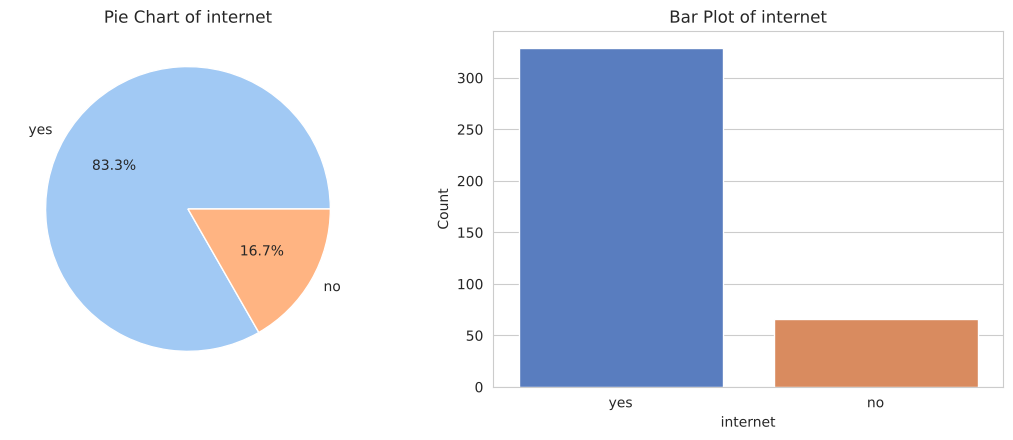

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].pie(freq_table, labels=freq_table.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'))
axes[0].set_title(f"Pie Chart of {cat_var}")

sns.barplot(x=freq_table.index, y=freq_table.values, hue=freq_table.index, palette='muted',
            legend=False, ax=axes[1])
axes[1].set_title(f"Bar Plot of {cat_var}")
axes[1].set_xlabel(cat_var)
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


## Q5. Frequency Distribution with Bin Intervals (Numerical Variable)
Binning `G3` (final grade, 0-20) into intervals and building a frequency table over the bins, then a
histogram and a box plot to check for outliers.

In [32]:
num_var = 'G3'
bins = [0, 5, 10, 15, 20]
bin_labels = ['0-5', '5-10', '10-15', '15-20']

g3_bins = pd.cut(df[num_var], bins=bins, labels=bin_labels, include_lowest=True)
binned_freq = g3_bins.value_counts().sort_index()
binned_freq_df = pd.DataFrame({'Bin_Interval': binned_freq.index, 'Frequency': binned_freq.values})
binned_freq_df


,Bin_Interval,Frequency
0,0-5,46
1,5-10,140
2,10-15,169
3,15-20,40


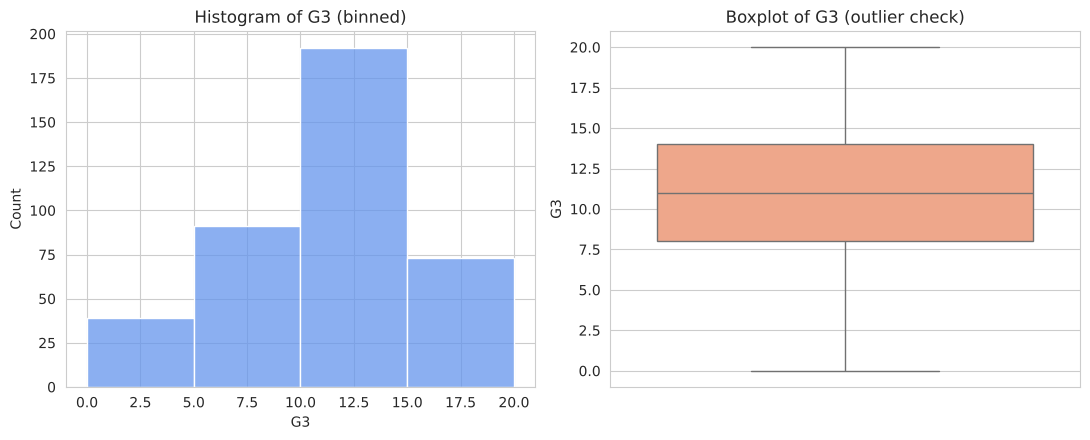

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.histplot(df[num_var], bins=bins, kde=False, color='cornflowerblue', ax=axes[0])
axes[0].set_title(f"Histogram of {num_var} (binned)")
axes[0].set_xlabel(num_var)

sns.boxplot(y=df[num_var], color='lightsalmon', ax=axes[1])
axes[1].set_title(f"Boxplot of {num_var} (outlier check)")

plt.tight_layout()
plt.show()


## Q6. Contingency Table (Two Categorical Variables)
Cross-tabulating `sex` and `internet`, then row and column percentages — the equivalent of R's
`prop.table(table(x, y), margin = 1)` (row %) and `margin = 2` (column %).

In [34]:
cat1, cat2 = 'sex', 'internet'

contingency = pd.crosstab(df[cat1], df[cat2])
row_pct = pd.crosstab(df[cat1], df[cat2], normalize='index') * 100     # prop.table(..., margin=1)
col_pct = pd.crosstab(df[cat1], df[cat2], normalize='columns') * 100   # prop.table(..., margin=2)

print("Contingency table (counts):")
print(contingency)
print("\nRow percentages (%):")
print(row_pct.round(2))
print("\nColumn percentages (%):")
print(col_pct.round(2))


Contingency table (counts):
internet  no  yes
sex              
F         38  172
M         28  157

Row percentages (%):
internet     no    yes
sex                   
F         18.10  81.90
M         15.14  84.86

Column percentages (%):
internet     no    yes
sex                   
F         57.58  52.28
M         42.42  47.72


## Q7. Stacked / Grouped Bar Plot (sex vs internet)

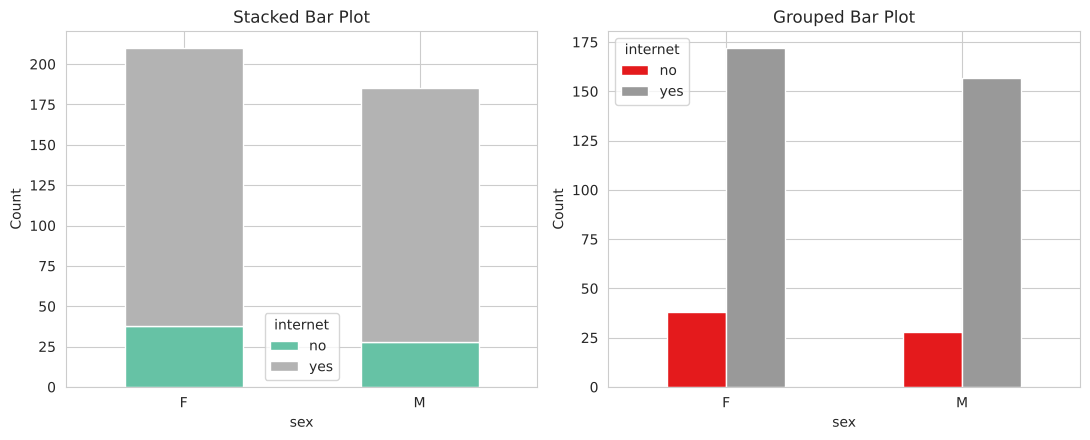

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

contingency.plot(kind='bar', stacked=True, ax=axes[0], colormap='Set2')
axes[0].set_title("Stacked Bar Plot")
axes[0].set_xlabel(cat1)
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=0)

contingency.plot(kind='bar', stacked=False, ax=axes[1], colormap='Set1')
axes[1].set_title("Grouped Bar Plot")
axes[1].set_xlabel(cat1)
axes[1].set_ylabel("Count")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


## Q8. Grouped Summary Statistics (Categorical + Numerical)
Mean, median and standard deviation of `G3` grouped by `studytime`, using `groupby().agg()`
— the Python equivalent of R's `aggregate(G3 ~ studytime, data = df, FUN = ...)`.

In [36]:
grouped_stats = df.groupby('studytime')['G3'].agg(['mean', 'median', 'std']).round(3)
grouped_stats.columns = ['Mean', 'Median', 'Std_Dev']
grouped_stats


,Mean,Median,Std_Dev
studytime,,,
1,10.048,10.0,4.956
2,10.172,11.0,4.218
3,11.400,12.0,4.640
4,11.259,12.0,5.281


## Q9. Side-by-Side Box Plots and Violin Plot
Visualizing how `G3` is distributed across the 4 `studytime` categories.

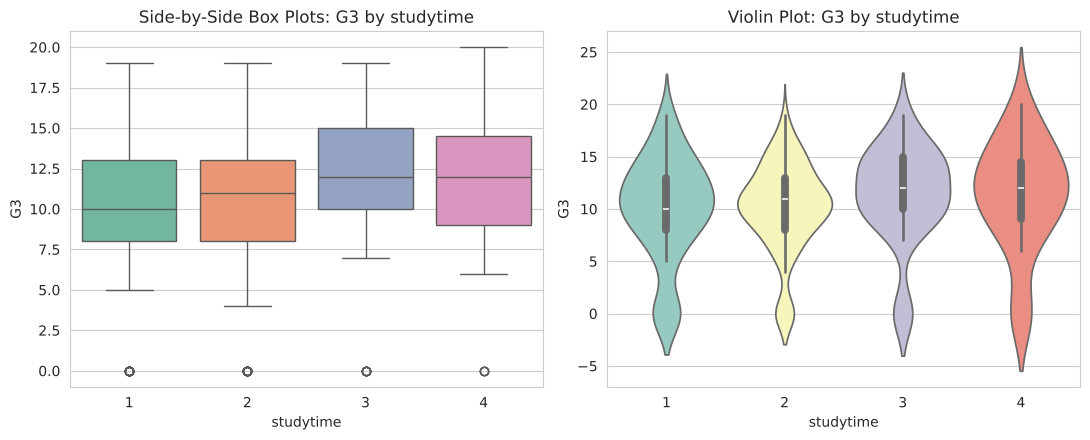

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.boxplot(x='studytime', y='G3', hue='studytime', data=df, palette='Set2', legend=False, ax=axes[0])
axes[0].set_title("Side-by-Side Box Plots: G3 by studytime")

sns.violinplot(x='studytime', y='G3', hue='studytime', data=df, palette='Set3', legend=False, ax=axes[1])
axes[1].set_title("Violin Plot: G3 by studytime")

plt.tight_layout()
plt.show()


## Q10. Pearson & Spearman Correlation + Scatter with Regression Line
Between `G1` (first period grade) and `G3` (final grade).

Pearson correlation:  r = 0.801, p = 9.001e-90
Spearman correlation: r = 0.878, p = 8.141e-128


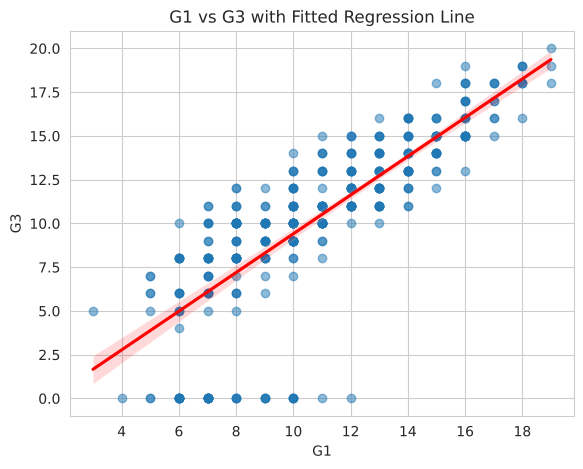

In [38]:
num1, num2 = 'G1', 'G3'

pearson_r, pearson_p = stats.pearsonr(df[num1], df[num2])   # equiv. to R's cor(x, y, method="pearson")
spearman_r, spearman_p = stats.spearmanr(df[num1], df[num2])  # equiv. to cor(x, y, method="spearman")

print(f"Pearson correlation:  r = {pearson_r:.3f}, p = {pearson_p:.4g}")
print(f"Spearman correlation: r = {spearman_r:.3f}, p = {spearman_p:.4g}")

plt.figure(figsize=(6.5, 5))
sns.regplot(x=num1, y=num2, data=df, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
plt.title(f"{num1} vs {num2} with Fitted Regression Line")
plt.show()


## Q11. Two Categorical + One Numerical: Summary Stats, Faceted Box Plot, Grouped Bar with Error Bars
Using `sex` and `internet` (categorical) with `G3` (numerical).

In [39]:
combo_stats = df.groupby(['sex', 'internet'])['G3'].agg(['mean', 'std']).round(3)
combo_stats.columns = ['Mean', 'Std_Dev']
combo_stats


Mean  Std_Dev
sex internet                 
F   no         9.184    4.099
    yes       10.140    4.728
M   no         9.714    5.025
    yes       11.140    4.368

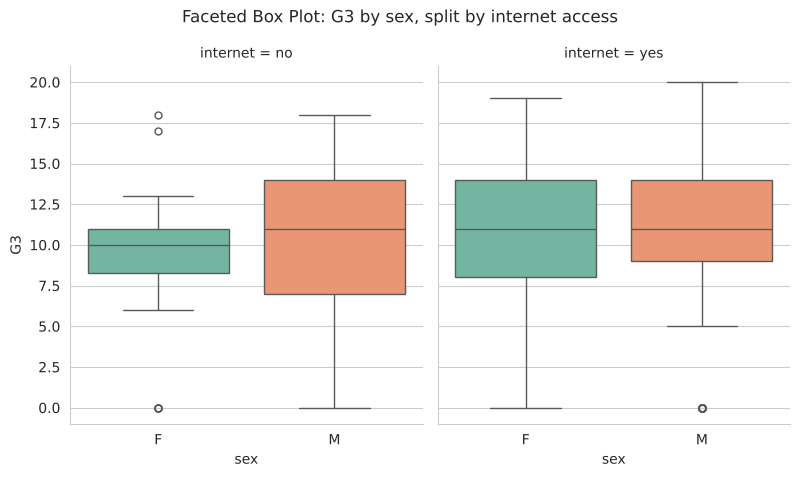

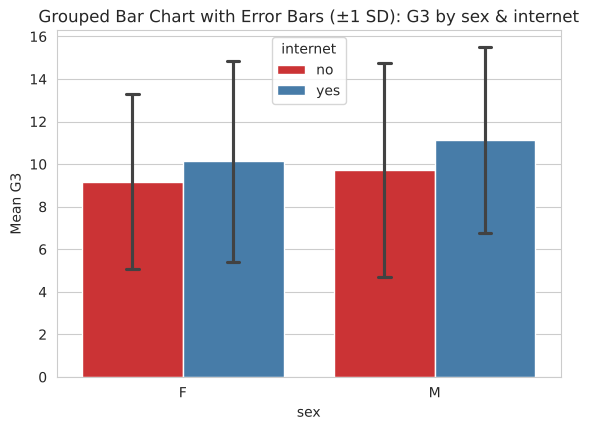

In [40]:
g = sns.catplot(x='sex', y='G3', hue='sex', col='internet', data=df, kind='box',
                 palette='Set2', height=4.5, aspect=0.9, legend=False)
g.fig.suptitle("Faceted Box Plot: G3 by sex, split by internet access", y=1.05)
plt.show()

plt.figure(figsize=(6.5, 4.5))
sns.barplot(x='sex', y='G3', hue='internet', data=df, palette='Set1', errorbar='sd', capsize=0.1)
plt.title("Grouped Bar Chart with Error Bars (±1 SD): G3 by sex & internet")
plt.ylabel("Mean G3")
plt.show()


## Q12. One Categorical + Two Numerical: Colored Scatter + Per-Category Correlation Matrix
Category: `internet`. Numerical features: `G1` and `G3`.

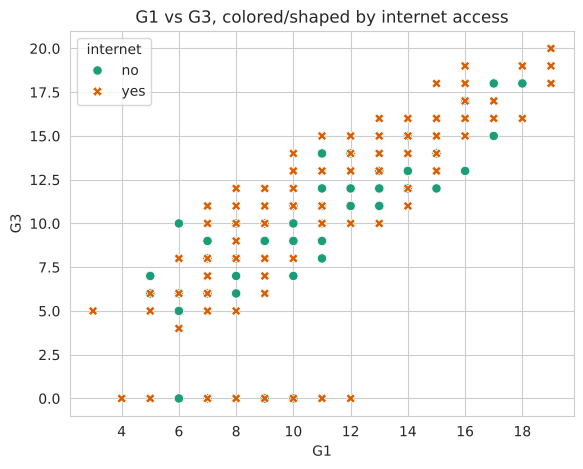

Correlation matrix for internet = 'no':
       G1     G3
G1  1.000  0.731
G3  0.731  1.000

Correlation matrix for internet = 'yes':
       G1     G3
G1  1.000  0.813
G3  0.813  1.000



In [41]:
plt.figure(figsize=(6.5, 5))
sns.scatterplot(x='G1', y='G3', hue='internet', style='internet', data=df, palette='Dark2', s=45)
plt.title("G1 vs G3, colored/shaped by internet access")
plt.show()

for level in sorted(df['internet'].unique()):
    sub = df[df['internet'] == level][['G1', 'G3']]
    print(f"Correlation matrix for internet = '{level}':")
    print(sub.corr().round(3))
    print()


## Q13. Correlation Matrix (3+ Numerical Features) + Heatmap

              G1     G2     G3  absences  studytime  failures
G1         1.000  0.852  0.801    -0.031      0.161    -0.355
G2         0.852  1.000  0.905    -0.032      0.136    -0.356
G3         0.801  0.905  1.000     0.034      0.098    -0.360
absences  -0.031 -0.032  0.034     1.000     -0.063     0.064
studytime  0.161  0.136  0.098    -0.063      1.000    -0.174
failures  -0.355 -0.356 -0.360     0.064     -0.174     1.000


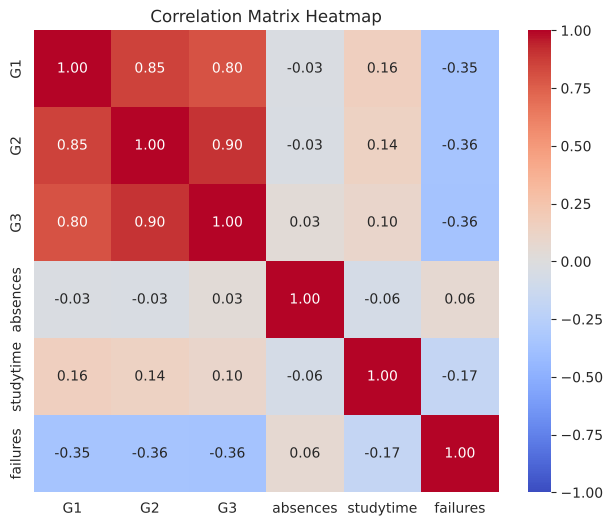

In [42]:
corr_features = ['G1', 'G2', 'G3', 'absences', 'studytime', 'failures']
corr_matrix = df[corr_features].corr()
print(corr_matrix.round(3))

plt.figure(figsize=(7.5, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title("Correlation Matrix Heatmap")
plt.show()


## Q14. Pairs Plot / Scatterplot Matrix

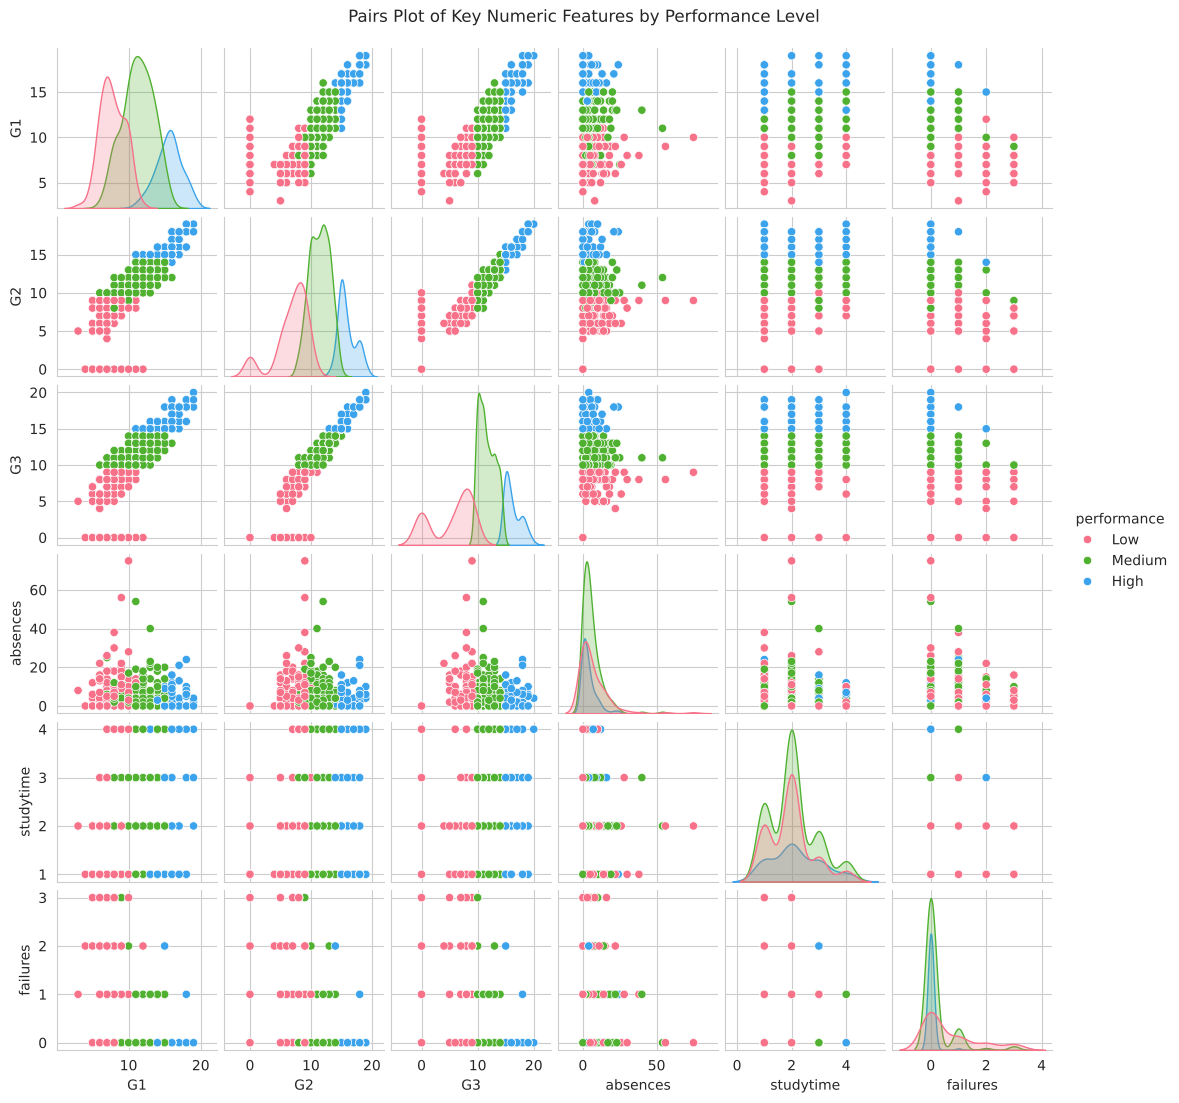

In [43]:
sns.pairplot(df[corr_features + ['performance']], hue='performance', palette='husl', height=1.8)
plt.suptitle("Pairs Plot of Key Numeric Features by Performance Level", y=1.02)
plt.show()


## 3D (Multivariate) Statistical Analysis
Correlation among `G1`, `G2`, `G3`, a 3D scatter plot of the same three grades colored by study time,
and a multiple linear regression predicting `G3` from `G1`, `G2` and `studytime`.

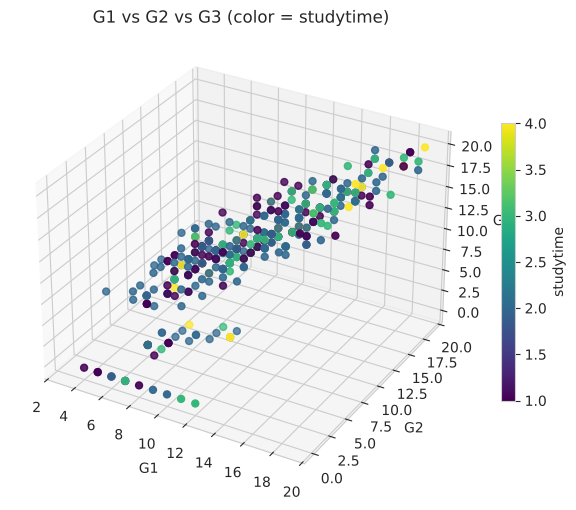

In [44]:
fig = plt.figure(figsize=(7.5, 6))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(df['G1'], df['G2'], df['G3'], c=df['studytime'], cmap='viridis', s=25)
ax.set_xlabel('G1'); ax.set_ylabel('G2'); ax.set_zlabel('G3')
ax.set_title("G1 vs G2 vs G3 (color = studytime)")
fig.colorbar(sc, ax=ax, shrink=0.6, label='studytime')
plt.show()


In [45]:
features_3d = ['G1', 'G2', 'studytime']
X = df[features_3d]
y = df['G3']

lin_reg = LinearRegression().fit(X, y)
print("Intercept:", round(lin_reg.intercept_, 3))
for feat, coef in zip(features_3d, lin_reg.coef_):
    print(f"Coefficient for {feat}: {coef:.3f}")
print(f"\nR-squared: {lin_reg.score(X, y):.3f}")


Intercept: -1.561
Coefficient for G1: 0.160
Coefficient for G2: 0.987
Coefficient for studytime: -0.169

R-squared: 0.823


## K-Means Clustering
Following the assignment's numbered steps.

**1-2. Load / view the dataset** — already loaded as `df` above.

In [46]:
df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,avg_grade,performance,schoolsup_enc,famsup_enc,paid_enc,activities_enc,nursery_enc,higher_enc,internet_enc,romantic_enc
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,5.666667,Low,1,0,0,0,1,1,0,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5.333333,Low,0,1,0,0,0,1,1,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,8.333333,Medium,1,0,1,0,1,1,1,0
3,GP,F,15,U,GT3,T,4,2,health,services,...,14.666667,High,0,1,1,1,1,1,1,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,8.666667,Medium,0,1,1,0,1,1,0,0


**3. Check missing values**

In [47]:
df.isnull().sum().sum()  # total missing values across the whole dataframe


np.int64(0)

**4. Check the dependent-variable distribution (table)**
Using `performance` (Low / Medium / High, derived from G3 in Phase 1) as the variable of interest.

In [48]:
df['performance'].value_counts()


performance
Medium    192
Low       130
High       73
Name: count, dtype: int64

**5. Select only numerical features for clustering (drop the rest)**

In [49]:
num_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
                'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
X_num = df[num_features]
X_num.head()


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,18,4,4,2,2,0,4,3,4,1,1,3,6,5,6,6
1,17,1,1,1,2,0,5,3,3,1,1,3,4,5,5,6
2,15,1,1,1,2,3,4,3,2,2,3,3,10,7,8,10
3,15,4,2,1,3,0,3,2,2,1,1,5,2,15,14,15
4,16,3,3,1,2,0,4,3,2,1,2,5,4,6,10,10


**6. Standardize the data**

In [50]:
scaler = StandardScaler()   # equiv. to R's scale()
X_scaled = scaler.fit_transform(X_num)
X_scaled[:5]


array([[ 1.02304645,  1.14385567,  1.36037064,  0.79225076, -0.04228585,
        -0.44994364,  0.06219406, -0.2360102 ,  0.8014793 , -0.54069866,
        -1.00378921, -0.39928949,  0.03642446, -1.78246688, -1.25479105,
        -0.96493392],
       [ 0.23837976, -1.60000865, -1.39997047, -0.64324947, -0.04228585,
        -0.44994364,  1.17886012, -0.2360102 , -0.09790798, -0.54069866,
        -1.00378921, -0.39928949, -0.21379577, -1.78246688, -1.52097927,
        -0.96493392],
       [-1.33095364, -1.60000865, -1.39997047, -0.64324947, -0.04228585,
         3.58932316,  0.06219406, -0.2360102 , -0.99729526,  0.58338539,
         0.55109996, -0.39928949,  0.53686493, -1.1791469 , -0.72241461,
        -0.0907392 ],
       [-1.33095364,  1.14385567, -0.47985677, -0.64324947,  1.15077909,
        -0.44994364, -1.054472  , -1.23841914, -0.99729526, -0.54069866,
        -1.00378921,  1.04106985, -0.464016  ,  1.23413302,  0.87471471,
         1.0020042 ],
       [-0.54628694,  0.22923423,  0

**7. Apply K-Means with centers = 2**

In [51]:
kmeans_k2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_scaled)
kmeans_k2


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 16)","[[-0

**8. Display K-Means results**

In [52]:
print("Cluster assignments (first 15 students):", kmeans_k2.labels_[:15])
print("\nCluster sizes:")
print(pd.Series(kmeans_k2.labels_).value_counts().sort_index())
print("\nInertia (WCSS) at k=2:", round(kmeans_k2.inertia_, 2))


Cluster assignments (first 15 students): [1 1 1 0 0 0 0 1 0 0 0 0 0 0 0]

Cluster sizes:
0    230
1    165
Name: count, dtype: int64

Inertia (WCSS) at k=2: 5460.87


**9. Display cluster centers**

In [53]:
centers_k2 = pd.DataFrame(kmeans_k2.cluster_centers_, columns=num_features)
centers_k2.round(3)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,-0.195,0.269,0.272,-0.169,0.170,-0.356,0.028,-0.105,-0.188,-0.213,-0.23,-0.077,-0.091,0.589,0.587,0.584
1,0.272,-0.375,-0.379,0.235,-0.238,0.497,-0.039,0.147,0.262,0.297,0.32,0.107,0.127,-0.821,-0.818,-0.814


**10-11. Calculate WCSS for K = 1 to 10 and plot the elbow curve**

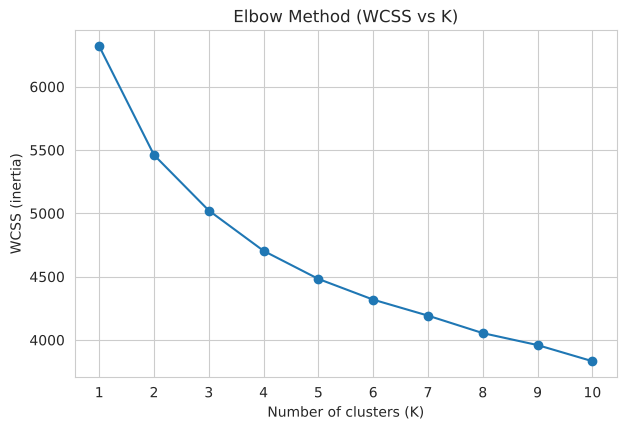

In [54]:
wcss = []
k_values = range(1, 11)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(7, 4.5))
plt.plot(list(k_values), wcss, marker='o')
plt.title("Elbow Method (WCSS vs K)")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS (inertia)")
plt.xticks(list(k_values))
plt.show()


**12. Apply K-Means based on the elbow recommendation**
The elbow curve flattens out noticeably around **K = 3**, so the final clustering uses `k = 3`.

Final K-Means (k=3) cluster sizes:
kmeans_cluster
0     98
1    146
2    151
Name: count, dtype: int64


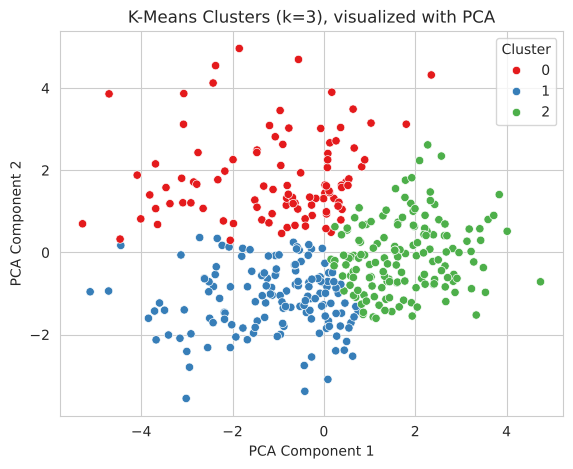

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
kmeans_cluster,,,,,,,,,,,,,,,,
0,17.05,2.90,2.64,1.68,1.69,0.50,3.82,3.70,3.99,2.58,3.84,3.90,8.53,10.07,10.02,9.80
1,16.74,2.16,2.06,1.48,2.13,0.51,3.92,3.00,2.92,1.13,1.80,3.50,5.16,8.55,7.95,7.02
2,16.42,3.22,2.89,1.26,2.17,0.05,4.05,3.16,2.72,1.11,1.76,3.38,4.41,13.73,13.83,14.10


In [55]:
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
df['kmeans_cluster'] = kmeans_final.labels_

print("Final K-Means (k=3) cluster sizes:")
print(df['kmeans_cluster'].value_counts().sort_index())

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)
plt.figure(figsize=(6.5, 5))
sns.scatterplot(x=pca_coords[:, 0], y=pca_coords[:, 1], hue=df['kmeans_cluster'], palette='Set1')
plt.title("K-Means Clusters (k=3), visualized with PCA")
plt.xlabel("PCA Component 1"); plt.ylabel("PCA Component 2")
plt.legend(title='Cluster')
plt.show()

df.groupby('kmeans_cluster')[num_features].mean().round(2)


## Hierarchical Clustering
Following the assignment's numbered steps.

**1-3. Load / view the dataset / check missing values** — same `df`, already confirmed clean above.

**4-5. Select only numerical attributes and standardize** — reusing `X_num` and `X_scaled` from the
K-Means section (same features, same scaling).

In [56]:
X_num.describe().T[['mean', 'std', 'min', 'max']].round(2)


,mean,std,min,max
age,16.70,1.28,15.0,22.0
Medu,2.75,1.09,0.0,4.0
Fedu,2.52,1.09,0.0,4.0
traveltime,1.45,0.70,1.0,4.0
studytime,2.04,0.84,1.0,4.0
failures,0.33,0.74,0.0,3.0
famrel,3.94,0.90,1.0,5.0
freetime,3.24,1.00,1.0,5.0
goout,3.11,1.11,1.0,5.0
Dalc,1.48,0.89,1.0,5.0


**6. Calculate Euclidean distance**

In [57]:
euclidean_dist = pdist(X_scaled, metric='euclidean')   # equiv. to R's dist(X, method="euclidean")
dist_matrix = squareform(euclidean_dist)
print("Distance matrix shape:", dist_matrix.shape)
print("Example distance (student 0 to student 1):", round(euclidean_dist[0], 3))


Distance matrix shape: (395, 395)
Example distance (student 0 to student 1): 4.474


**7-8. Hierarchical clustering with Single, Complete, Average and Ward linkage — dendrograms**
`scipy.cluster.hierarchy.linkage()` is the equivalent of R's `hclust()`; the `method` argument selects
the linkage type.

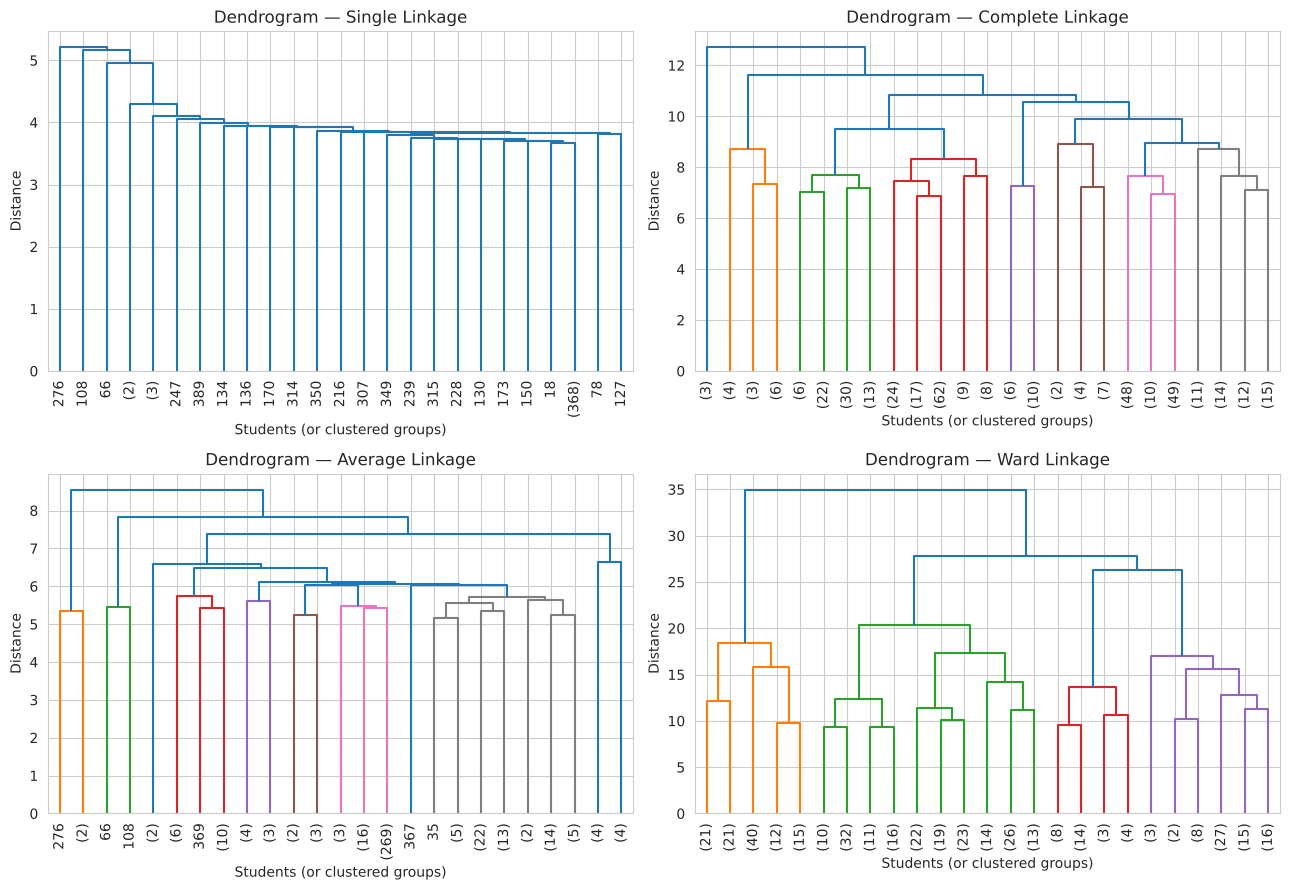

In [58]:
linkage_methods = ['single', 'complete', 'average', 'ward']
linkages = {m: linkage(X_scaled, method=m) for m in linkage_methods}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, m in zip(axes.ravel(), linkage_methods):
    dendrogram(linkages[m], truncate_mode='lastp', p=25, leaf_rotation=90, ax=ax)
    ax.set_title(f"Dendrogram — {m.capitalize()} Linkage")
    ax.set_xlabel("Students (or clustered groups)")
    ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()


**9-10. Cut each tree into 3 clusters (`cutree` / `fcluster`) and show cluster sizes**

In [59]:
cluster_assignments = {}
for m in linkage_methods:
    labels = fcluster(linkages[m], t=3, criterion='maxclust')   # equiv. to R's cutree(hc, k=3)
    cluster_assignments[m] = labels
    print(f"{m.capitalize()} linkage — cluster sizes:")
    print(pd.Series(labels).value_counts().sort_index())
    print()

# Keeping the Ward-linkage assignment on the dataframe (most balanced clusters, comparable to K-Means)
df['hc_cluster'] = cluster_assignments['ward']
df.groupby('hc_cluster')[num_features].mean().round(2)


Single linkage — cluster sizes:
1    393
2      1
3      1
Name: count, dtype: int64

Complete linkage — cluster sizes:
1      3
2     13
3    379
Name: count, dtype: int64

Average linkage — cluster sizes:
1      3
2      2
3    390
Name: count, dtype: int64

Ward linkage — cluster sizes:
1    109
2    186
3    100
Name: count, dtype: int64



,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
hc_cluster,,,,,,,,,,,,,,,,
1,16.66,3.23,2.78,1.23,2.32,0.15,4.01,3.25,2.86,1.13,1.76,3.33,5.24,14.54,14.50,14.76
2,16.54,2.42,2.39,1.54,2.05,0.13,4.01,3.04,2.90,1.24,1.95,3.51,4.25,9.74,9.34,8.89
3,17.02,2.84,2.49,1.51,1.69,0.91,3.75,3.58,3.76,2.32,3.50,3.89,8.94,9.13,9.13,8.51


In [60]:
# Comparing K-Means (k=3) with Hierarchical (Ward, k=3) cluster assignments
comparison = pd.crosstab(df['kmeans_cluster'], df['hc_cluster'])
comparison.index.name = 'KMeans cluster'
comparison.columns.name = 'Hierarchical (Ward) cluster'
comparison


Hierarchical (Ward) cluster,1,2,3
KMeans cluster,,,
0,3,20,75
1,9,114,23
2,97,52,2


## Conclusion (Phase 2)

- **Summary statistics (Q2-3):** `G3` has a moderate left skew (about -0.73), pulled by the students who scored 0; `absences` is heavily
  right-skewed with a handful of high-absence outliers, which the box plot confirms.
- **Categorical distribution (Q4):** most students have internet access at home, visible in both the pie
  chart and bar plot.
- **Binned numerical distribution (Q5):** the bulk of students land in the 10-15 grade bucket.
- **Contingency table (Q6-7):** `sex` and `internet` access show only mild association once row/column
  percentages are compared.
- **Grouped stats (Q8-9):** average `G3` rises from about 10.0 at study time 1 to about 11.3 at study times 3 and 4, and the box/violin plots show a similar spread at every study-time level.
- **Correlation (Q10):** `G1` and `G3` are strongly, positively correlated (both Pearson and Spearman),
  confirming first-period performance is a strong predictor of the final grade.
- **Two-categorical analysis (Q11-12):** grade differences by `sex`/`internet` combinations are modest;
  the `G1` vs `G3` relationship stays strongly positive within both internet-access groups.
- **Correlation matrix / pairs plot (Q13-14):** `G1`, `G2` and `G3` are all tightly correlated with each
  other, while `absences`, `studytime` and `failures` show weaker, more scattered relationships with the
  grades.
- **3D analysis:** the multiple regression using `G1`, `G2` and `studytime` explains most of the
  variation in `G3`, dominated by the two prior grades.
- **K-Means:** the elbow plot flattens around K = 3, giving 3 reasonably balanced student groups
  separated mainly by prior grades and failures.
- **Hierarchical clustering:** Ward linkage (cut at 3 clusters) produces group sizes and profiles broadly
  similar to K-Means, while single-linkage chains most points into one dominant cluster — a well-known
  effect of single linkage on this kind of data.


# Phase 3a – Principal Component Analysis (PCA)

**Name:** Amogh Kumar Sharma
**Reg No:** 23BDS0063

Phase 3a continues the same notebook and uses the same cleaned `df` from Phase 1 and Phase 2.

**What is PCA, in simple words?** Our data has 16 number columns (grades, absences, study time, etc.).
Many of them move together (for example G1, G2 and G3). PCA mixes these columns into a smaller set of
*new* columns called **principal components**. The first component captures as much of the
differences between students as possible, the second captures the next most, and so on. This lets us
describe the students with just a few columns instead of 16, without losing much information.

Steps in this phase:
14. Select the numeric columns and standardize them
15. Apply PCA and look at the variance explained by each component
16. Scree plot and cumulative variance plot (how many components to keep)
17. Loadings (which original columns make up each component)
18. Plot the students on the first components (2D and 3D)
19. Biplot
20. Re-run K-Means on the PCA scores and compare with Phase 2

## 14. Select Numeric Columns and Standardize
PCA is affected by the *scale* of the columns (absences go up to 75 while studytime only goes 1 to 4),
so every column is standardized first (mean 0, standard deviation 1). This is the same
`num_features` / `X_scaled` that was used for clustering in Phase 2.

In [61]:
# same 16 numeric columns as used in Phase 2 clustering
num_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
                'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

X_pca_input = df[num_features]
scaler_pca = StandardScaler()          # equiv. to R's scale()
X_std = scaler_pca.fit_transform(X_pca_input)

print("Data used for PCA:", X_std.shape, "(students x numeric columns)")
print("Mean of every column after scaling (should be ~0):", np.round(X_std.mean(axis=0), 6).max())
print("Std of every column after scaling (should be 1):", np.round(X_std.std(axis=0), 6).min(),
      "to", np.round(X_std.std(axis=0), 6).max())

Data used for PCA: (395, 16) (students x numeric columns)
Mean of every column after scaling (should be ~0): -0.0
Std of every column after scaling (should be 1): 1.0 to 1.0


## 15. Apply PCA – Variance Explained by Each Component
Fitting PCA with all 16 components first, so we can see how much each one explains.
`pca.explained_variance_` are the **eigenvalues** (R: `prcomp()$sdev^2`) and
`pca.explained_variance_ratio_` is the share of total variation each component carries
(R: `summary(prcomp(...))`).

In [62]:
pca_full = PCA(n_components=len(num_features), random_state=42)
pc_scores_full = pca_full.fit_transform(X_std)

pc_names = [f"PC{i}" for i in range(1, len(num_features) + 1)]
variance_table = pd.DataFrame({
    'Eigenvalue': pca_full.explained_variance_,
    'Variance_Explained_%': pca_full.explained_variance_ratio_ * 100,
    'Cumulative_Variance_%': np.cumsum(pca_full.explained_variance_ratio_) * 100
}, index=pc_names)

variance_table.round(3)

,Eigenvalue,Variance_Explained_%,Cumulative_Variance_%
PC1,3.404,21.223,21.223
PC2,2.098,13.077,34.300
PC3,1.562,9.736,44.035
PC4,1.283,7.998,52.033
PC5,1.173,7.310,59.344
PC6,1.015,6.330,65.673
PC7,0.933,5.816,71.489
PC8,0.901,5.616,77.105
PC9,0.772,4.812,81.917
PC10,0.719,4.481,86.398


## 16. Scree Plot and Cumulative Variance Plot – How Many Components to Keep?
Three common rules are checked:
- **Scree plot (elbow):** keep the components before the curve flattens out.
- **Kaiser rule:** keep components with eigenvalue greater than 1 (they explain more than a single original column would).
- **Cumulative variance:** keep enough components to reach about 80% of the total variation.

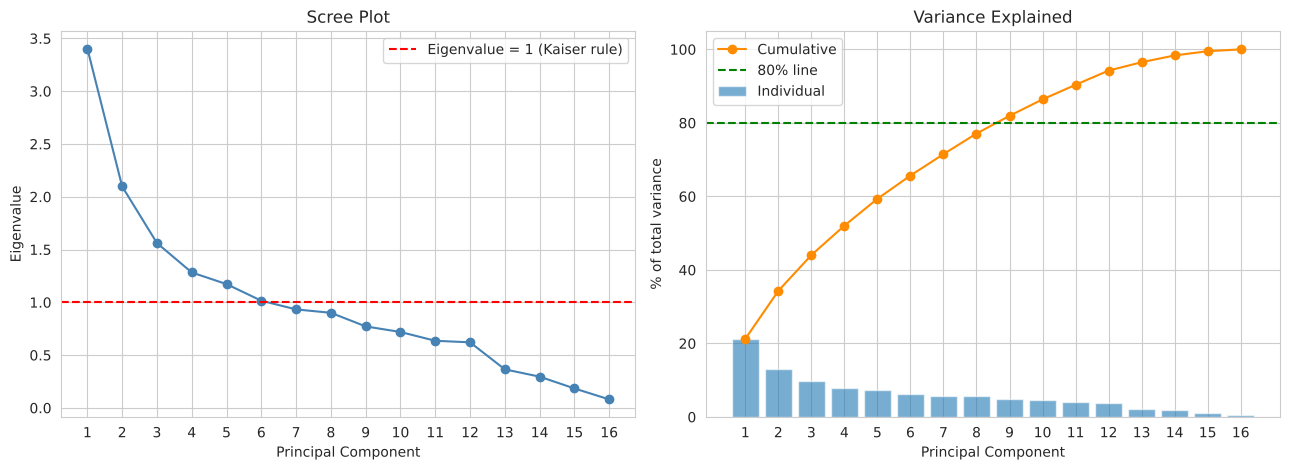

Components with eigenvalue > 1 (Kaiser rule): 6
Components needed to reach 80% variance: 9


In [63]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Scree plot
axes[0].plot(range(1, 17), pca_full.explained_variance_, marker='o', color='steelblue')
axes[0].axhline(1, color='red', linestyle='--', label='Eigenvalue = 1 (Kaiser rule)')
axes[0].set_title("Scree Plot")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Eigenvalue")
axes[0].set_xticks(range(1, 17))
axes[0].legend()

# Cumulative variance plot
cum_var = np.cumsum(pca_full.explained_variance_ratio_) * 100
axes[1].bar(range(1, 17), pca_full.explained_variance_ratio_ * 100, alpha=0.6, label='Individual')
axes[1].plot(range(1, 17), cum_var, marker='o', color='darkorange', label='Cumulative')
axes[1].axhline(80, color='green', linestyle='--', label='80% line')
axes[1].set_title("Variance Explained")
axes[1].set_xlabel("Principal Component")
axes[1].set_ylabel("% of total variance")
axes[1].set_xticks(range(1, 17))
axes[1].legend()

plt.tight_layout()
plt.show()

n_kaiser = int((pca_full.explained_variance_ > 1).sum())
n_80 = int(np.argmax(cum_var >= 80) + 1)
print(f"Components with eigenvalue > 1 (Kaiser rule): {n_kaiser}")
print(f"Components needed to reach 80% variance: {n_80}")

**Choosing the number of components.** The final choice is made from the numbers printed above:
the 80% rule gives the number of components needed to keep most of the information, and the Kaiser
rule gives a stricter count. The next cell stores the choice in `n_comp` and uses the **80% rule**.

In [64]:
n_comp = n_80          # components kept (80% variance rule)
print(f"Keeping {n_comp} components -> {cum_var[n_comp-1]:.1f}% of the total variation "
      f"with {n_comp} columns instead of {len(num_features)}")

pca_final = PCA(n_components=n_comp, random_state=42)
pc_scores = pca_final.fit_transform(X_std)
pc_cols = [f"PC{i}" for i in range(1, n_comp + 1)]
pca_df = pd.DataFrame(pc_scores, columns=pc_cols, index=df.index)
pca_df['performance'] = df['performance'].values
pca_df['kmeans_cluster'] = df['kmeans_cluster'].values
pca_df.head()

Keeping 9 components -> 81.9% of the total variation with 9 columns instead of 16


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,performance,kmeans_cluster
0,-1.237779,-0.631418,2.284534,-0.476026,0.915623,-0.449974,1.178671,-0.850598,0.669799,Low,1
1,-2.047520,-2.314948,-0.201799,0.873457,0.712254,-0.156897,-0.128189,-0.043922,-1.464245,Low,1
2,-2.415952,-0.829879,-1.307950,-0.279088,-0.486246,0.660775,-1.865384,0.142745,-0.488154,Medium,1
3,2.670242,-1.195463,0.160069,-0.422397,-1.183210,0.350316,-0.281958,1.468446,0.323474,High,2
4,-0.083111,-0.994260,1.233626,0.330133,-0.785698,0.886560,-0.174628,0.500687,-0.250137,Medium,1


## 17. Loadings – What Is Each Component Made Of?
A **loading** shows how strongly an original column contributes to a component (R: `prcomp()$rotation`).
A large positive or negative number means that column matters a lot for that component;
a number near 0 means it barely matters.

Loadings (correlation between each column and each component):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
age,-0.306,0.097,-0.315,-0.200,0.606,0.133,0.088,0.002,0.432
Medu,0.424,0.308,0.670,-0.128,0.109,0.019,0.091,-0.099,0.183
Fedu,0.383,0.286,0.705,-0.093,-0.008,0.058,0.121,-0.103,0.255
traveltime,-0.268,0.053,-0.303,-0.071,-0.288,-0.115,0.708,-0.338,0.173
studytime,0.288,-0.314,0.008,-0.018,0.362,-0.321,0.262,0.612,0.050
failures,-0.586,0.005,-0.162,-0.025,0.127,0.162,-0.302,-0.082,0.394
famrel,0.036,-0.037,0.017,0.627,0.417,0.232,0.371,-0.166,-0.224
freetime,-0.118,0.420,-0.011,0.583,0.148,-0.110,-0.264,-0.220,0.026
goout,-0.306,0.543,0.126,0.185,0.290,-0.353,0.019,0.116,-0.092
Dalc,-0.308,0.725,-0.113,-0.101,-0.145,-0.045,0.083,0.174,-0.011


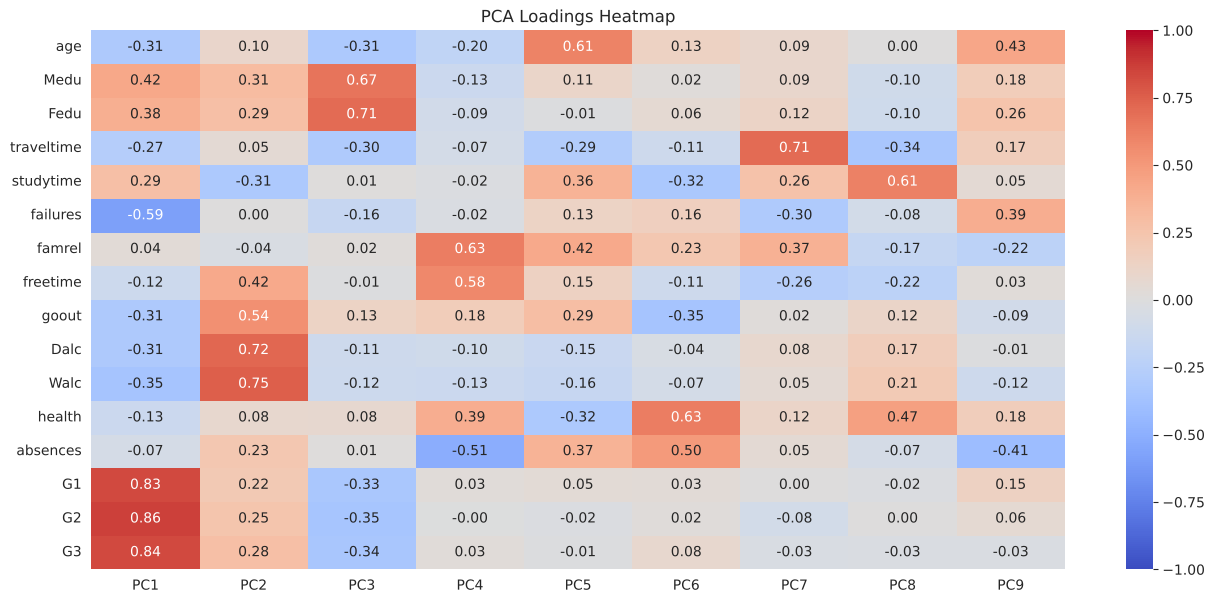

PC1 is mostly made up of: G2 (+0.86), G3 (+0.84), G1 (+0.83), failures (-0.59)
PC2 is mostly made up of: Walc (+0.75), Dalc (+0.72), goout (+0.54), freetime (+0.42)
PC3 is mostly made up of: Fedu (+0.71), Medu (+0.67), G2 (-0.35), G3 (-0.34)


In [65]:
# loadings = eigenvectors scaled by sqrt(eigenvalue) -> also equal to the correlation of each
# original column with each component
loadings = pd.DataFrame(
    pca_final.components_.T * np.sqrt(pca_final.explained_variance_),
    index=num_features, columns=pc_cols
)
print("Loadings (correlation between each column and each component):")
display(loadings.round(3))

plt.figure(figsize=(1.3 * n_comp + 4, 7))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title("PCA Loadings Heatmap")
plt.show()

# top 4 columns (by size of loading) for the first three components
for pc in pc_cols[:3]:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(f"{pc} is mostly made up of:", ", ".join(f"{c} ({loadings.loc[c, pc]:+.2f})" for c in top))

## 18. Students on the First Principal Components
Each student now has a score on every component. Plotting the first two (and three) shows how the
students are spread out, coloured by their performance level from Phase 1 (`Low` / `Medium` / `High`).

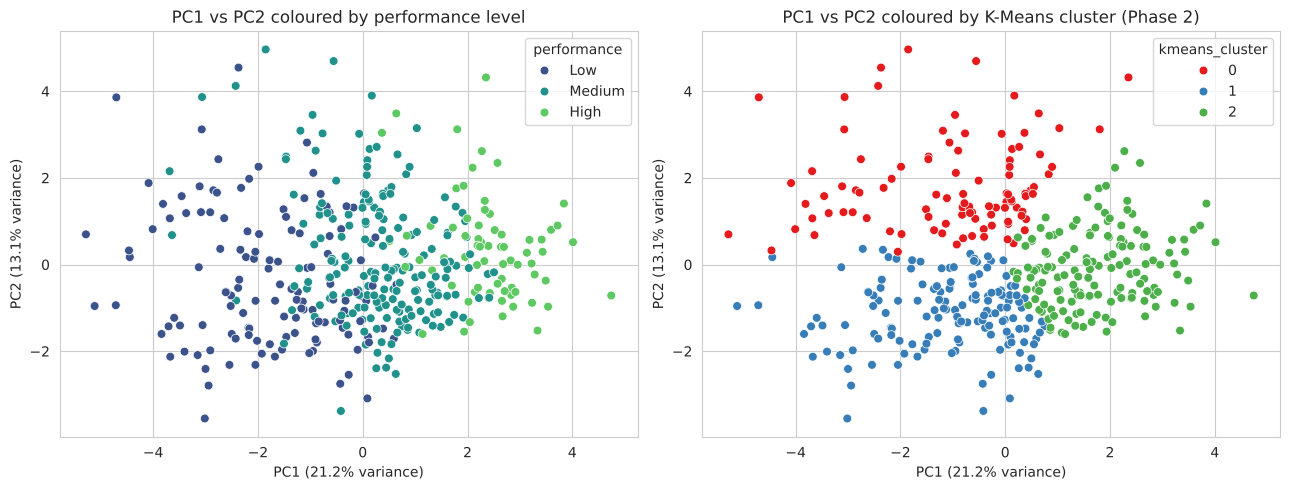

In [66]:
order = ['Low', 'Medium', 'High']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='performance', hue_order=order,
                palette='viridis', s=40, ax=axes[0])
axes[0].set_title("PC1 vs PC2 coloured by performance level")
axes[0].set_xlabel(f"PC1 ({pca_final.explained_variance_ratio_[0]*100:.1f}% variance)")
axes[0].set_ylabel(f"PC2 ({pca_final.explained_variance_ratio_[1]*100:.1f}% variance)")

sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='kmeans_cluster', palette='Set1', s=40, ax=axes[1])
axes[1].set_title("PC1 vs PC2 coloured by K-Means cluster (Phase 2)")
axes[1].set_xlabel(axes[0].get_xlabel())
axes[1].set_ylabel(axes[0].get_ylabel())

plt.tight_layout()
plt.show()

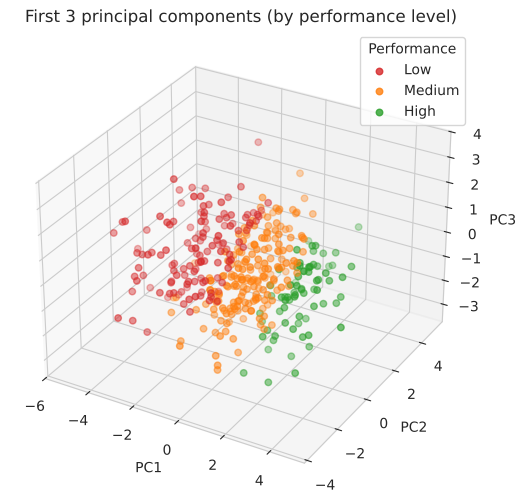

Average component scores for each performance level:


,PC1,PC2,PC3,PC4
performance,,,,
Low,-1.782,-0.358,0.542,-0.094
Medium,0.300,0.114,-0.163,-0.024
High,2.384,0.338,-0.536,0.231


In [67]:
# 3D view of the first three components
fig = plt.figure(figsize=(7.5, 6))
ax = fig.add_subplot(111, projection='3d')
colors = {'Low': 'tab:red', 'Medium': 'tab:orange', 'High': 'tab:green'}
for level in order:
    sub = pca_df[pca_df['performance'] == level]
    ax.scatter(sub['PC1'], sub['PC2'], sub['PC3'], c=colors[level], label=level, s=22, alpha=0.8)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
ax.set_title("First 3 principal components (by performance level)")
ax.legend(title='Performance')
plt.show()

print("Average component scores for each performance level:")
pca_df.groupby('performance')[pc_cols[:4]].mean().loc[order].round(3)

## 19. Biplot
A biplot draws the students (dots) and the original columns (arrows) on the same picture.
Arrows pointing the same way mean those columns go up and down together; arrows pointing opposite
ways mean they behave in opposite directions; a long arrow means the column matters a lot for these two components.

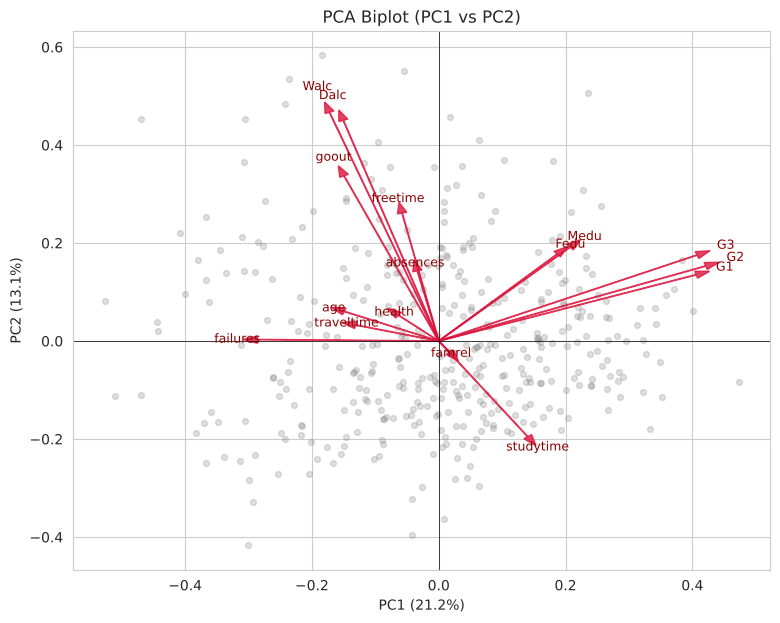

In [68]:
fig, ax = plt.subplots(figsize=(9, 7))

# students (scaled so they fit with the arrows)
scale_x = 1.0 / (pc_scores[:, 0].max() - pc_scores[:, 0].min())
scale_y = 1.0 / (pc_scores[:, 1].max() - pc_scores[:, 1].min())
ax.scatter(pc_scores[:, 0] * scale_x, pc_scores[:, 1] * scale_y, alpha=0.25, s=18, color='gray')

# arrows for each original column
for feat in num_features:
    x, y = pca_final.components_[0, num_features.index(feat)], pca_final.components_[1, num_features.index(feat)]
    ax.arrow(0, 0, x * 0.9, y * 0.9, color='crimson', head_width=0.015, alpha=0.8)
    ax.text(x * 1.0, y * 1.0, feat, color='darkred', fontsize=9, ha='center', va='center')

ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel(f"PC1 ({pca_final.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca_final.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("PCA Biplot (PC1 vs PC2)")
plt.show()

## 20. K-Means on the PCA Scores vs the Original Data
Phase 2 clustered the students using all 16 standardized columns. Here K-Means (K = 3) is repeated on
only the first `n_comp` principal components, and the two results are compared using
the **silhouette score** (higher = clearer, better-separated groups) and a cross-table.

In [69]:
# K-Means on the PCA scores (k = 3, same settings as Phase 2)
km_pca = KMeans(n_clusters=3, random_state=42, n_init=10).fit(pc_scores)
df['pca_kmeans_cluster'] = km_pca.labels_

print("Cluster sizes (K-Means on PCA scores):")
print(df['pca_kmeans_cluster'].value_counts().sort_index())

sil_original = silhouette_score(X_std, df['kmeans_cluster'])
sil_pca = silhouette_score(pc_scores, df['pca_kmeans_cluster'])
print(f"\nSilhouette score, K-Means on original 16 columns : {sil_original:.3f}")
print(f"Silhouette score, K-Means on {n_comp} PCA components   : {sil_pca:.3f}")

comparison_pca = pd.crosstab(df['kmeans_cluster'], df['pca_kmeans_cluster'])
comparison_pca.index.name = 'K-Means (original data)'
comparison_pca.columns.name = 'K-Means (PCA scores)'
print("\nHow the two clusterings line up:")
comparison_pca

Cluster sizes (K-Means on PCA scores):
pca_kmeans_cluster
0    157
1     99
2    139
Name: count, dtype: int64

Silhouette score, K-Means on original 16 columns : 0.113
Silhouette score, K-Means on 9 PCA components   : 0.138

How the two clusterings line up:


K-Means (PCA scores),0,1,2
K-Means (original data),,,
0,0,96,2
1,143,3,0
2,14,0,137


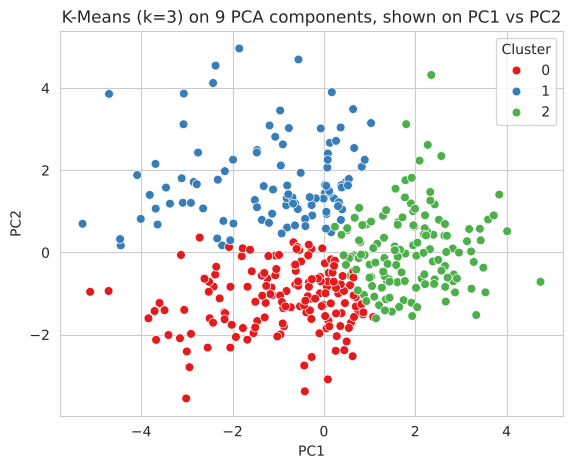

,G1,G2,G3,failures,absences,studytime
pca_kmeans_cluster,,,,,,
0,8.75,8.24,7.40,0.46,5.05,2.11
1,9.83,9.73,9.49,0.54,8.49,1.70
2,14.12,14.21,14.47,0.05,4.47,2.19


In [70]:
plt.figure(figsize=(6.5, 5))
sns.scatterplot(x=pc_scores[:, 0], y=pc_scores[:, 1], hue=df['pca_kmeans_cluster'], palette='Set1', s=40)
plt.title(f"K-Means (k=3) on {n_comp} PCA components, shown on PC1 vs PC2")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend(title='Cluster')
plt.show()

df.groupby('pca_kmeans_cluster')[['G1', 'G2', 'G3', 'failures', 'absences', 'studytime']].mean().round(2)

## Conclusion (Phase 3a)

- **Standardizing first:** the 16 numeric columns were put on the same scale so that large-valued columns like `absences` did not dominate the result.
- **Variance explained:** PC1 carries about 21% of the total variation, PC2 about 13% and PC3 about 10%. The variation is spread over many components, so these columns are only partly overlapping (apart from the three grades).
- **How many components to keep:** the Kaiser rule (eigenvalue above 1) suggests 6 components, while the 80% rule needs 9 components (about 82% of the information). The 80% rule was used, reducing 16 columns to 9.
- **PC1 = academic performance:** `G1`, `G2` and `G3` have the largest positive loadings (about 0.83 to 0.86) and `failures` is negative (about -0.59). A student with a high PC1 score has strong grades and few past failures.
- **PC2 = social life and alcohol use:** `Walc`, `Dalc`, `goout` and `freetime` load highest, so PC2 mostly separates students who go out and drink more from those who do not.
- **PC3 = parents' education:** `Medu` and `Fedu` load highest (about 0.67 to 0.71).
- **Performance levels separate along PC1:** the average PC1 score is about -1.8 for `Low`, 0.3 for `Medium` and 2.4 for `High` performers, so one component alone already shows the grade groups well. PC2 and PC3 do not separate them.
- **Biplot:** the three grade arrows point the same way (they move together), `failures` points the opposite way, and the alcohol / going-out arrows point mostly upward along PC2, almost at a right angle to the grades, which means they are largely unrelated to academic performance here.
- **Clustering after PCA:** K-Means (K = 3) on the 9 components gave groups of 157, 99 and 139 students and agreed with the Phase 2 clustering for about 95% of students. The silhouette score improved slightly (0.113 on the original data vs 0.138 on the PCA scores), because PCA removes some of the noise from the weaker columns.

This completes Phase 3a (PCA).

# Phase 3b - Simple Linear Regression

**Name:** Amogh Kumar Sharma
**Reg No:** 23BDS0063

Phase 3b uses the same cleaned `df` as the earlier phases.

**What is simple linear regression, in simple words?** It draws the best straight line through the points of two columns, so we can predict one column from the other. The line is written as `y = intercept + slope * x`.

Here the first period grade `G1` is used to predict the final grade `G3`. Phase 2 already showed these two are strongly related (Pearson r = 0.80).

Steps in this phase:
21. Select the independent and dependent variable
22. Split the data into training (80%) and testing (20%)
23. Train the Linear Regression model
24. Predict on the test data
25. Evaluate with MAE, MSE, RMSE and R-squared
26. Plot the actual points and the regression line
27. Write the regression equation

## 21. Select Variables
Independent variable (x): `G1`. Dependent variable (y): `G3`.

In [71]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df[['G1']]      # sklearn needs x as a 2D table
y = df['G3']

print("Correlation between G1 and G3:", round(df['G1'].corr(df['G3']), 3))

Correlation between G1 and G3: 0.801


## 22. Train-Test Split
80% of the students are used to train the model and 20% are kept aside to test it. `random_state=42` keeps the split the same every time.

In [72]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape[0], "students")
print("Testing set :", X_test.shape[0], "students")

Training set: 316 students
Testing set : 79 students


## 23. Train the Model

In [73]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1.13]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['G1']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.024
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


## 24. Predictions on the Test Data

In [74]:
y_pred = model.predict(X_test)

# actual vs predicted for the first 10 test students
results = pd.DataFrame({'G1': X_test['G1'].values, 'Actual G3': y_test.values, 'Predicted G3': y_pred.round(2)})
results.head(10)

,G1,Actual G3,Predicted G3
0,8,10,7.01
1,14,12,13.79
2,3,5,1.36
3,8,10,7.01
4,9,9,8.14
5,12,13,11.53
6,19,18,19.44
7,9,6,8.14
8,8,0,7.01
9,11,14,10.40


## 25. Model Evaluation
- MAE: average size of the error
- MSE: average of the squared errors (big mistakes count more)
- RMSE: square root of MSE, in the same units as the grade
- R-squared: share of the variation in G3 that the model explains (1 is perfect)

In [75]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE)      : {mae:.3f}")
print(f"Mean Squared Error (MSE)       : {mse:.3f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:.3f}")
print(f"R-squared (R2) score           : {r2:.3f}")

Mean Absolute Error (MAE)      : 1.855
Mean Squared Error (MSE)       : 6.163
Root Mean Squared Error (RMSE) : 2.482
R-squared (R2) score           : 0.699


## 26. Actual Data Points and Regression Line

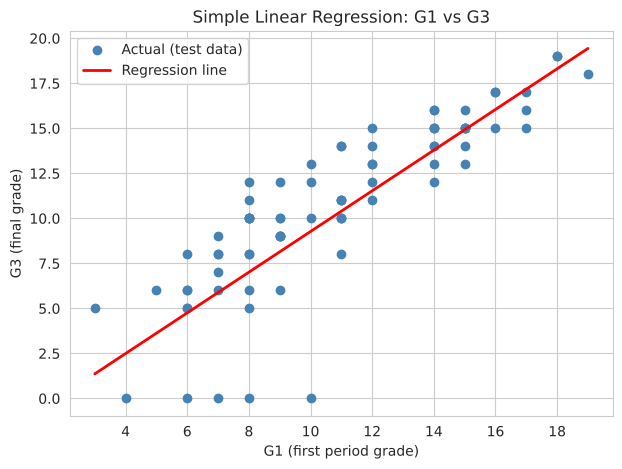

In [76]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, color='steelblue', label='Actual (test data)')

# line drawn across the full G1 range
x_line = pd.DataFrame({'G1': np.linspace(df['G1'].min(), df['G1'].max(), 100)})
plt.plot(x_line, model.predict(x_line), color='red', linewidth=2, label='Regression line')

plt.title("Simple Linear Regression: G1 vs G3")
plt.xlabel("G1 (first period grade)")
plt.ylabel("G3 (final grade)")
plt.legend()
plt.show()

## 27. Regression Equation

In [77]:
print("Intercept:", round(model.intercept_, 3))
print("Coefficient (slope):", round(model.coef_[0], 3))
print(f"\nG3 = {model.intercept_:.3f} + {model.coef_[0]:.3f} * G1")

Intercept: -2.024
Coefficient (slope): 1.13

G3 = -2.024 + 1.130 * G1


## Conclusion (Phase 3b)

- Simple linear regression was used to predict the final grade (`G3`) from the first period grade (`G1`). The data was split 80/20 (316 training and 79 testing students).
- The fitted line is `G3 = -2.024 + 1.130 * G1`. Each extra mark in G1 goes with about 1.13 more marks in G3.
- On the test data the average error (MAE) is about 1.86 marks and RMSE is about 2.48 marks. R-squared is 0.70, so G1 alone explains about 70% of the variation in G3.
- The remaining 30% is not explained. Part of it comes from the students with a G3 of 0, whom a straight line cannot predict, so the points far below the line in the plot are mostly those students.
- In Phase 2 the multiple regression with G1, G2 and studytime reached an R-squared of 0.82. G2 is the grade closest to the final one, so adding it improves the fit.

This completes Phase 3b (Simple Linear Regression).